# ComplexHeatmap simple quickstart method

In [1]:
# quick-start guide for plotting a DGE heatmap from a DGE table and a relative expression table via ComplexHeatmap
# full user-guide can be found here: https://jokergoo.github.io/ComplexHeatmap-reference/book/

library(ComplexHeatmap)
library(circlize)

Loading required package: grid

ComplexHeatmap version 2.18.0
Bioconductor page: http://bioconductor.org/packages/ComplexHeatmap/
Github page: https://github.com/jokergoo/ComplexHeatmap
Documentation: http://jokergoo.github.io/ComplexHeatmap-reference

If you use it in published research, please cite either one:
- Gu, Z. Complex Heatmap Visualization. iMeta 2022.
- Gu, Z. Complex heatmaps reveal patterns and correlations in multidimensional 
    genomic data. Bioinformatics 2016.


The new InteractiveComplexHeatmap package can directly export static 
complex heatmaps into an interactive Shiny app with zero effort. Have a try!

This message can be suppressed by:
  suppressPackageStartupMessages(library(ComplexHeatmap))


circlize version 0.4.16
CRAN page: https://cran.r-project.org/package=circlize
Github page: https://github.com/jokergoo/circlize
Documentation: https://jokergoo.github.io/circlize_book/book/

If you use it in published research, please cite:
Gu, Z. circlize implements a

In [7]:
# import normalized counts table (or whatever relative expression data)
# e.g. where the first column is gene name and the remaining columns are relative expression values for each sample in the experiment

norm.counts <- read.csv("251125_Heatmap.csv")
genes <- norm.counts$Gene # save gene names
norm.counts$Gene <- NULL
Annotations <- norm.counts$Annotation # save annotations
norm.counts$Annotation <- NULL
norm.counts <- as.matrix(norm.counts) # convert to numeric matrix
rownames(norm.counts) <- genes # make gene names the row names
rm(genes)
head(norm.counts)
tail(norm.counts)

,SrfFlox1,SrfFlox2,SrfFlox3,SrfFlox4,SrfKO1,SrfKO2,SrfKO3,SrfKO4
Myh11,32843.288,32241.170,40023.404,41530.398,12623.601,9638.817,10157.929,6658.499
Cnn1,5295.886,5493.503,5595.055,7150.443,2267.955,1995.774,1775.418,1287.649
Actg2,4474.599,5711.486,5914.568,7695.555,2625.726,1970.135,1656.407,1183.874
Des,6747.671,7436.760,7443.021,8690.976,2674.465,3204.168,2323.652,1930.414
Tpm2,7738.880,8773.383,9833.081,11418.904,4390.209,3071.926,3199.655,2060.661
Acta2,28351.548,29899.122,31916.228,36330.507,15823.315,9482.961,11790.924,7528.932


,SrfFlox1,SrfFlox2,SrfFlox3,SrfFlox4,SrfKO1,SrfKO2,SrfKO3,SrfKO4
Col6a3,8773.3144,9265.1118,8844.9263,9110.4749,8448.0542,6937.304,6061.7856,4463.3542
Col15a1,3520.6538,3812.1635,3541.5606,4021.9760,3194.5291,3091.492,2632.8869,2094.5468
Vcl,8167.4101,8418.5276,8437.4584,8477.6713,6962.0097,6518.313,6339.8045,6141.7448
Myh9,22993.8047,22594.1656,23584.6752,24876.0521,20854.4000,21295.673,19818.3516,22038.2747
Actn4,12378.1837,12061.7122,12664.7139,13369.4560,11497.9194,11508.421,11146.1157,11617.4280
Calml3,177.3742,163.9095,139.1135,146.9431,239.5508,291.472,287.7739,327.2068


In [8]:
# center and scale the rlog counts table (i.e. produce Z-score expression values across the samples, for each gene)
# note: t() will transpose the matrix
# so, here, we are transposing the matrix, center and scaling with scale(), then transposing back
# the reason for this is that scale() by default wants to scale each column vector (samples here), but we want to scale gene-wise

scaled.norm.counts <- t(scale(t(norm.counts)))

head(scaled.norm.counts)


,SrfFlox1,SrfFlox2,SrfFlox3,SrfFlox4,SrfKO1,SrfKO2,SrfKO3,SrfKO4
Myh11,0.6505914,0.6099073,1.1357395,1.237565,-0.7156183,-0.9172950,-0.8822195,-1.118670
Cnn1,0.6382676,0.7259708,0.7710400,1.461327,-0.7055393,-0.8263343,-0.9241287,-1.140603
Actg2,0.2391729,0.7576676,0.8427980,1.589376,-0.5358622,-0.8106814,-0.9421940,-1.140276
Des,0.6101935,0.8588085,0.8610673,1.311314,-0.8593700,-0.6682597,-0.9859392,-1.127815
Tpm2,0.4015667,0.6924698,0.9904577,1.436392,-0.5400823,-0.9107845,-0.8748670,-1.195153
Acta2,0.6098845,0.7454723,0.9221973,1.308946,-0.4877536,-1.0432520,-0.8410441,-1.214451


In [9]:
# Export normalized counts file if desired

write.csv(scaled.norm.counts,file="scaled.norm.counts.csv") # keeps the rownames

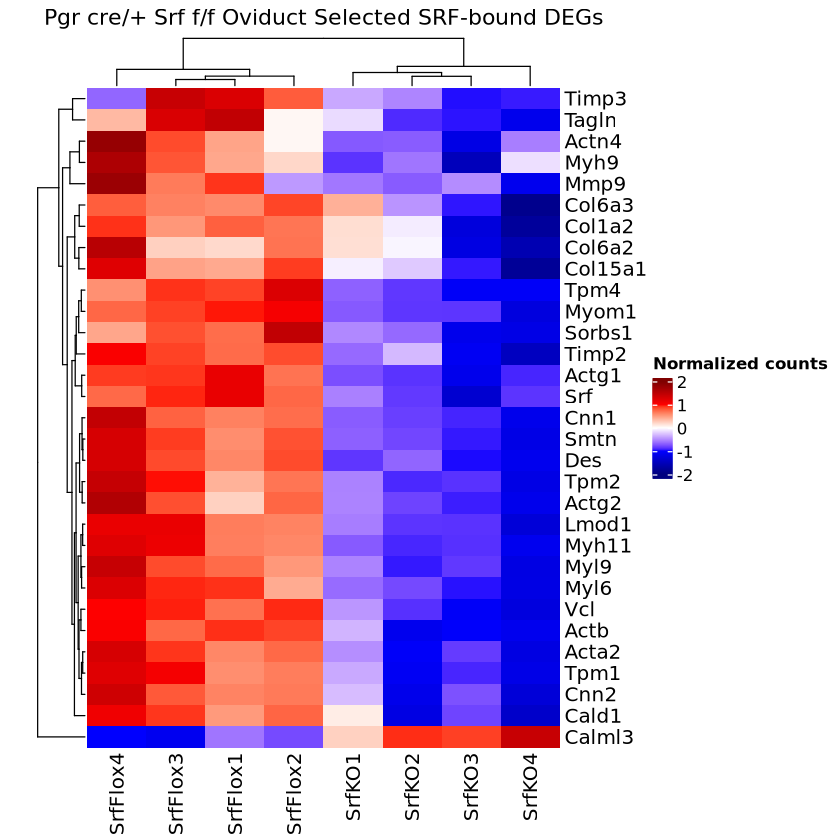

In [10]:
set.seed(1) # set seed for reproducibility
Heatmap(scaled.norm.counts, 
        clustering_distance_rows = "euclidean", # this is the default method
        width = unit(10, "cm"), # width of the heatmap
        name="Normalized counts", # name of the legend i.e. colorbar
        col = colorRamp2(c(-2, -1, 0, 1, 2), 
                         c("#00007F", "blue", "white", "red", "#7F0000")), # this is a custom color scale
        show_row_names=TRUE,
        show_column_names=TRUE,
        column_title="Pgr cre/+ Srf f/f Oviduct Selected SRF-bound DEGs", # set your own title
        cluster_columns=TRUE)

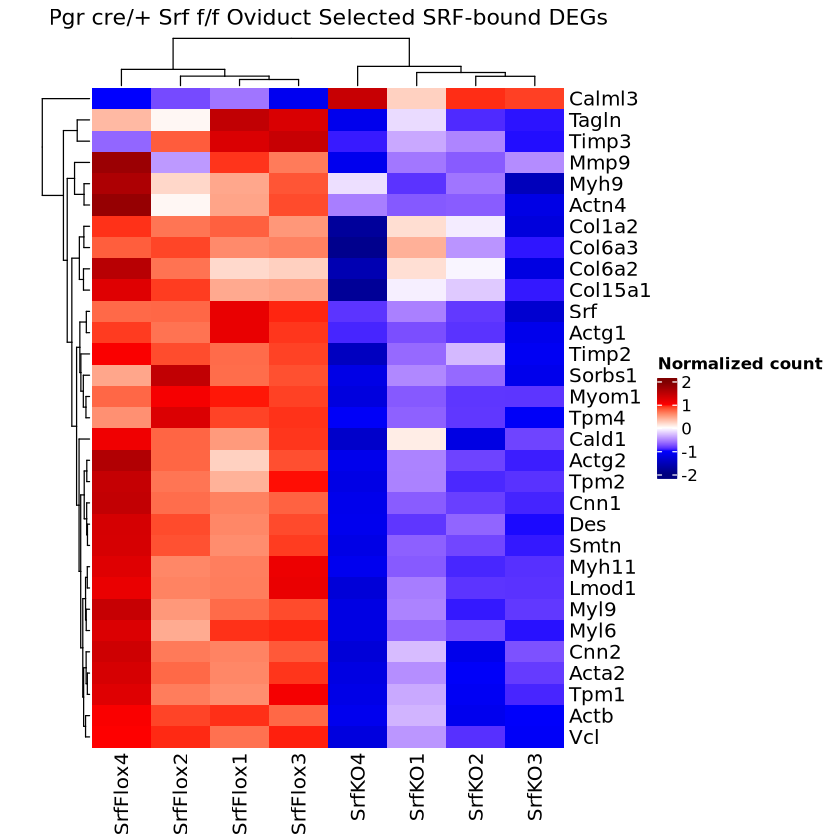

In [11]:
#Cluster but do not reorder dendrograms
set.seed(1) # set seed for reproducibility
Heatmap(scaled.norm.counts, 
        clustering_distance_rows = "euclidean", # this is the default method
        width = unit(10, "cm"), # width of the heatmap
        name="Normalized count", # name of the legend i.e. colorbar
        col = colorRamp2(c(-2, -1, 0, 1, 2), 
                         c("#00007F", "blue", "white", "red", "#7F0000")), # this is a custom color scale
        show_row_names=TRUE,
        show_column_names=TRUE,
        column_title="Pgr cre/+ Srf f/f Oviduct Selected SRF-bound DEGs", # set your own title
        cluster_columns=TRUE,
        row_dend_reorder = FALSE,
        column_dend_reorder = FALSE)


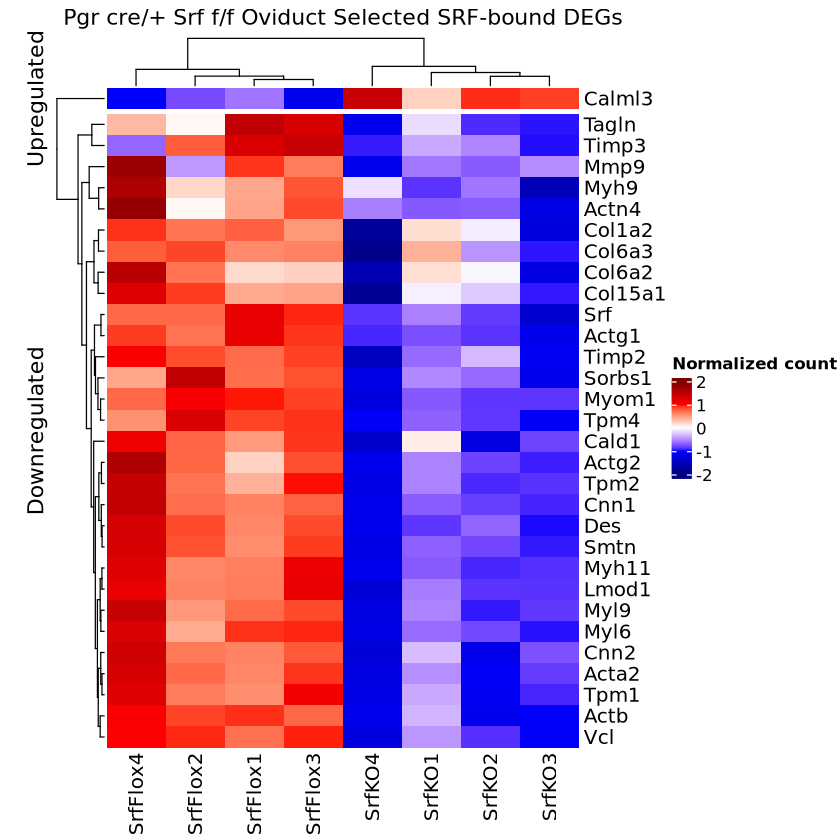

In [13]:
#Cluster but do not reorder dendrograms AND split rows (and name them)
set.seed(1) # set seed for reproducibility
Heatmap(scaled.norm.counts, 
        clustering_distance_rows = "euclidean", # this is the default method
        width = unit(10, "cm"), # width of the heatmap
        name="Normalized count", # name of the legend i.e. colorbar
        col = colorRamp2(c(-2, -1, 0, 1, 2), 
                         c("#00007F", "blue", "white", "red", "#7F0000")), # this is a custom color scale
        show_row_names=TRUE,
        show_column_names=TRUE,
        column_title="Pgr cre/+ Srf f/f Oviduct Selected SRF-bound DEGs", # set your own title
        row_split = 2, # splits rows into the number indicated based on dendrogram
        row_title = c("Upregulated", "Downregulated"), # name the two sections we split it into
        cluster_columns=TRUE,
        row_dend_reorder = FALSE,
        column_dend_reorder = FALSE)


Warning message in order(as.numeric(gsub("row", "", rownames(scaled.norm.counts)))):
“NAs introduced by coercion”
Warning message in order(as.numeric(gsub("column", "", colnames(scaled.norm.counts)))):
“NAs introduced by coercion”


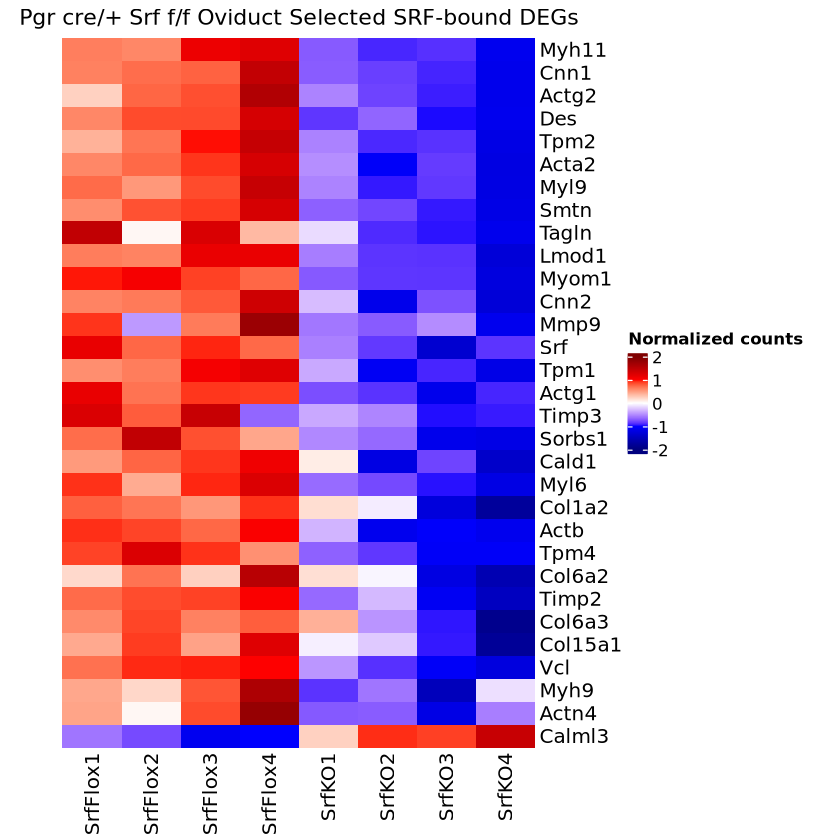

In [14]:
#Stop clustering rows and columns - keep original order 
set.seed(1) # set seed for reproducibility
Heatmap(scaled.norm.counts, 
        width = unit(10, "cm"), # width of the heatmap
        name="Normalized counts", # name of the legend i.e. colorbar
        col = colorRamp2(c(-2, -1, 0, 1, 2), 
                         c("#00007F", "blue", "white", "red", "#7F0000")), # this is a custom color scale
        show_row_names=TRUE,
        show_column_names=TRUE,
        column_title="Pgr cre/+ Srf f/f Oviduct Selected SRF-bound DEGs", # set your own title
        row_order = order(as.numeric(gsub("row", "", rownames(scaled.norm.counts)))), # orders rows by table order rather than clustering
        column_order = order(as.numeric(gsub("column", "", colnames(scaled.norm.counts))))) #orders columns by table order rather than clustering

Warning message in order(as.numeric(gsub("row", "", rownames(scaled.norm.counts)))):
“NAs introduced by coercion”
Warning message in order(as.numeric(gsub("column", "", colnames(scaled.norm.counts)))):
“NAs introduced by coercion”


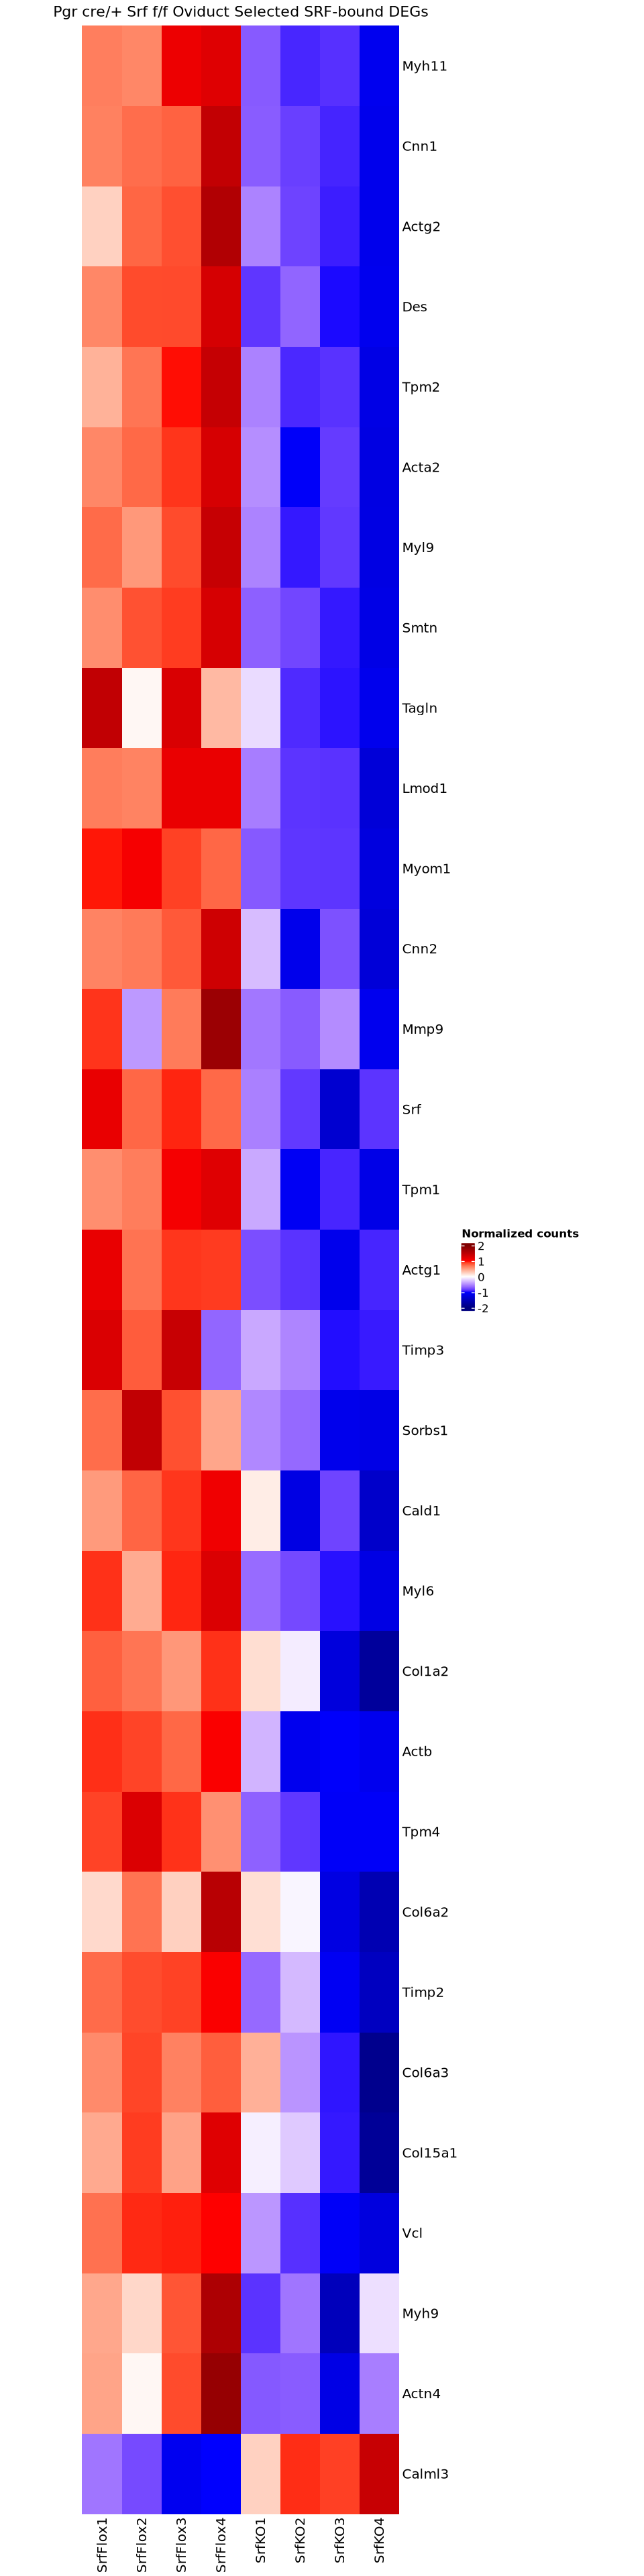

In [15]:
# Adjust plot size
saved <- options(repr.plot.width = 8, repr.plot.height = 32) # Make the plots bigger from here on out, save old options

#Stop clustering rows and columns
set.seed(1) # set seed for reproducibility
Heatmap(scaled.norm.counts, 
        width = unit(10, "cm"), # width of the heatmap
        name="Normalized counts", # name of the legend i.e. colorbar
        col = colorRamp2(c(-2, -1, 0, 1, 2), 
                         c("#00007F", "blue", "white", "red", "#7F0000")), # this is a custom color scale
        show_row_names=TRUE,
        show_column_names=TRUE,
        column_title="Pgr cre/+ Srf f/f Oviduct Selected SRF-bound DEGs", # set your own title
        row_order = order(as.numeric(gsub("row", "", rownames(scaled.norm.counts)))), # orders rows by table order rather than clustering
        column_order = order(as.numeric(gsub("column", "", colnames(scaled.norm.counts))))) #orders columns by table order rather than clustering

options(saved) # restore old settings

Warning message in order(as.numeric(gsub("row", "", rownames(scaled.norm.counts)))):
“NAs introduced by coercion”
Warning message in order(as.numeric(gsub("column", "", colnames(scaled.norm.counts)))):
“NAs introduced by coercion”


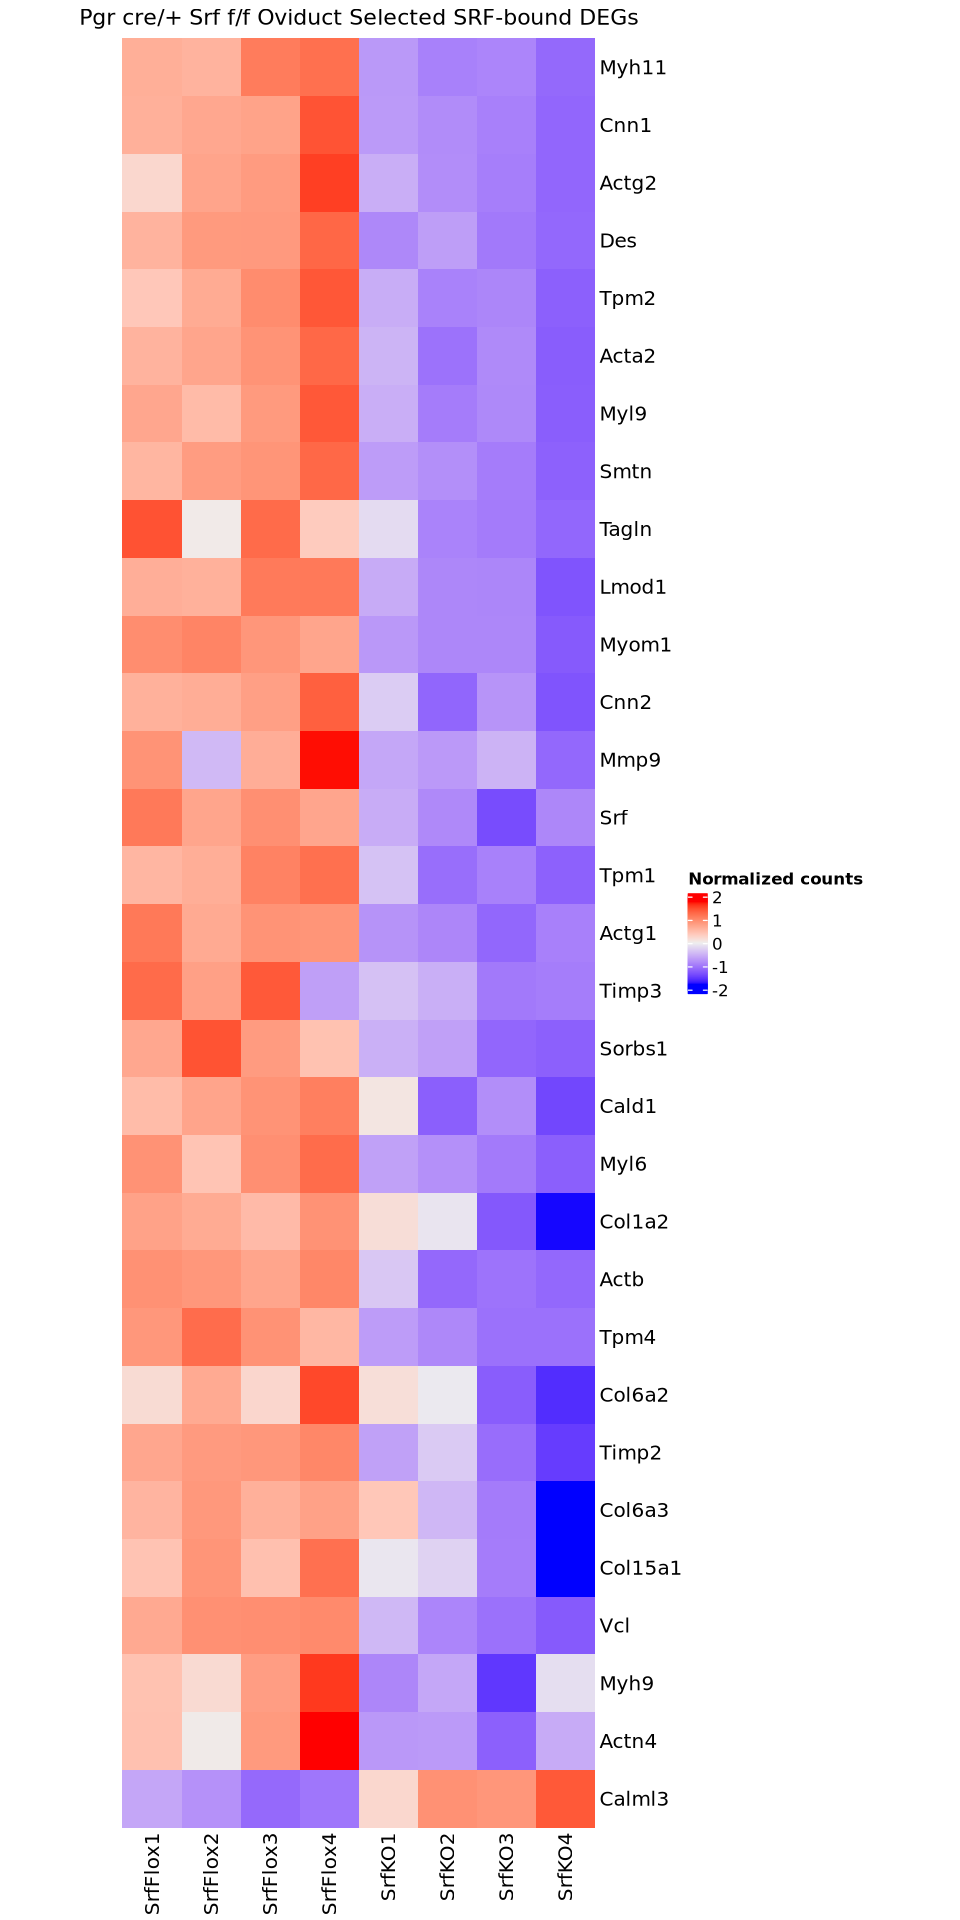

In [68]:
saved <- options(repr.plot.width = 8, repr.plot.height = 16) # Make the plots bigger from here on out, save old options

# Change to default color scheme

# Stop clustering rows and columns
set.seed(1) # set seed for reproducibility
Heatmap(scaled.norm.counts, 
        width = unit(10, "cm"), # width of the heatmap
        name="Normalized counts", # name of the legend i.e. colorbar
        show_row_names=TRUE,
        show_column_names=TRUE,
        column_title="Pgr cre/+ Srf f/f Oviduct Selected SRF-bound DEGs", # set your own title
        row_order = order(as.numeric(gsub("row", "", rownames(scaled.norm.counts)))), # orders rows by table order rather than clustering
        column_order = order(as.numeric(gsub("column", "", colnames(scaled.norm.counts))))) #orders columns by table order rather than clustering

options(saved) # restore old settings

In [17]:
# FYI: to add back annotations
scaled.norm.counts.annotated <- cbind(scaled.norm.counts, Annotations)
head(scaled.norm.counts.annotated)

,SrfFlox1,SrfFlox2,SrfFlox3,SrfFlox4,SrfKO1,SrfKO2,SrfKO3,SrfKO4,Annotations
Myh11,0.650591420832941,0.609907284138266,1.13573953183817,1.23756457919226,-0.715618287857727,-0.91729500837435,-0.882219477953145,-1.11867004181641,Cytoskeleton and contractility
Cnn1,0.638267619196905,0.725970807519616,0.77103999401085,1.46132664152291,-0.705539256745087,-0.826334311713555,-0.924128740576105,-1.14060275321553,Cytoskeleton and contractility
Actg2,0.239172947114646,0.757667572897951,0.842798018146687,1.58937563034842,-0.535862231731332,-0.810681402833188,-0.94219404842207,-1.14027648552111,Cytoskeleton and contractility
Des,0.61019352696353,0.858808466301488,0.861067303805261,1.31131426574347,-0.859369975127938,-0.668259687011318,-0.985939185741344,-1.12781471493315,Cytoskeleton and contractility
Tpm2,0.401566719984322,0.69246983714182,0.990457669209042,1.43639245162378,-0.540082272125826,-0.910784499138417,-0.874866965862132,-1.19515294083259,Cytoskeleton and contractility
Acta2,0.609884468184985,0.745472326581044,0.922197292459165,1.30894623800743,-0.487753587761753,-1.0432520325383,-0.841044060070178,-1.21445064486239,Cytoskeleton and contractility


# Alternative ComplexHeatmap method using draw function to add annotations

In [18]:
# Following: https://www.biostars.org/p/286187/#286507
# Load one more package
library(cluster)

In [20]:
# Load and view data
df <- read.csv("251125_Heatmap.csv")
head(df)

,Annotation,Gene,SrfFlox1,SrfFlox2,SrfFlox3,SrfFlox4,SrfKO1,SrfKO2,SrfKO3,SrfKO4
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,Cytoskeleton and contractility,Myh11,32843.288,32241.170,40023.404,41530.398,12623.601,9638.817,10157.929,6658.499
2,Cytoskeleton and contractility,Cnn1,5295.886,5493.503,5595.055,7150.443,2267.955,1995.774,1775.418,1287.649
3,Cytoskeleton and contractility,Actg2,4474.599,5711.486,5914.568,7695.555,2625.726,1970.135,1656.407,1183.874
4,Cytoskeleton and contractility,Des,6747.671,7436.760,7443.021,8690.976,2674.465,3204.168,2323.652,1930.414
5,Cytoskeleton and contractility,Tpm2,7738.880,8773.383,9833.081,11418.904,4390.209,3071.926,3199.655,2060.661
6,Cytoskeleton and contractility,Acta2,28351.548,29899.122,31916.228,36330.507,15823.315,9482.961,11790.924,7528.932


In [21]:
# center and scale the rlog counts table (i.e. produce Z-score expression values across the samples, for each gene)
# note: t() will transpose the matrix, and we are specifying that we are only taking the data starting in the 3rd column
# so, here, we are transposing the matrix, center and scaling with scale(), then transposing back
# the reason for this is that scale() by default wants to scale each column vector (samples here), but we want to scale gene-wise

heat <- t(scale(t(df[,3:ncol(df)])))
rownames(heat) <- df$Gene # assign row names as gene names
head(heat) # check our work

,SrfFlox1,SrfFlox2,SrfFlox3,SrfFlox4,SrfKO1,SrfKO2,SrfKO3,SrfKO4
Myh11,0.6505914,0.6099073,1.1357395,1.237565,-0.7156183,-0.9172950,-0.8822195,-1.118670
Cnn1,0.6382676,0.7259708,0.7710400,1.461327,-0.7055393,-0.8263343,-0.9241287,-1.140603
Actg2,0.2391729,0.7576676,0.8427980,1.589376,-0.5358622,-0.8106814,-0.9421940,-1.140276
Des,0.6101935,0.8588085,0.8610673,1.311314,-0.8593700,-0.6682597,-0.9859392,-1.127815
Tpm2,0.4015667,0.6924698,0.9904577,1.436392,-0.5400823,-0.9107845,-0.8748670,-1.195153
Acta2,0.6098845,0.7454723,0.9221973,1.308946,-0.4877536,-1.0432520,-0.8410441,-1.214451


In [22]:
# Export normalized counts file if desired

write.csv(heat,file="heat_scaled.norm.counts.csv") # keeps the rownames

In [25]:
# Set annotations
  ColAnn <- data.frame(colnames(heat))
  colnames(ColAnn) <- c("Sample")
  ColAnn <- HeatmapAnnotation(df=ColAnn, which="col")

RowAnn <- data.frame(df$Annotation)
  colnames(RowAnn) <- c("Annotation")
  colours <- list("Annotation"=c("Cytoskeleton and contractility"="coral", "Extracellular matrix"="darkcyan"))
  RowAnn <- HeatmapAnnotation(df=RowAnn, col=colours, which="row")

myBreaks <- seq(-3, 3, length.out=100)
myCol <- colorRampPalette(c("blue", "white", "red"))(100)


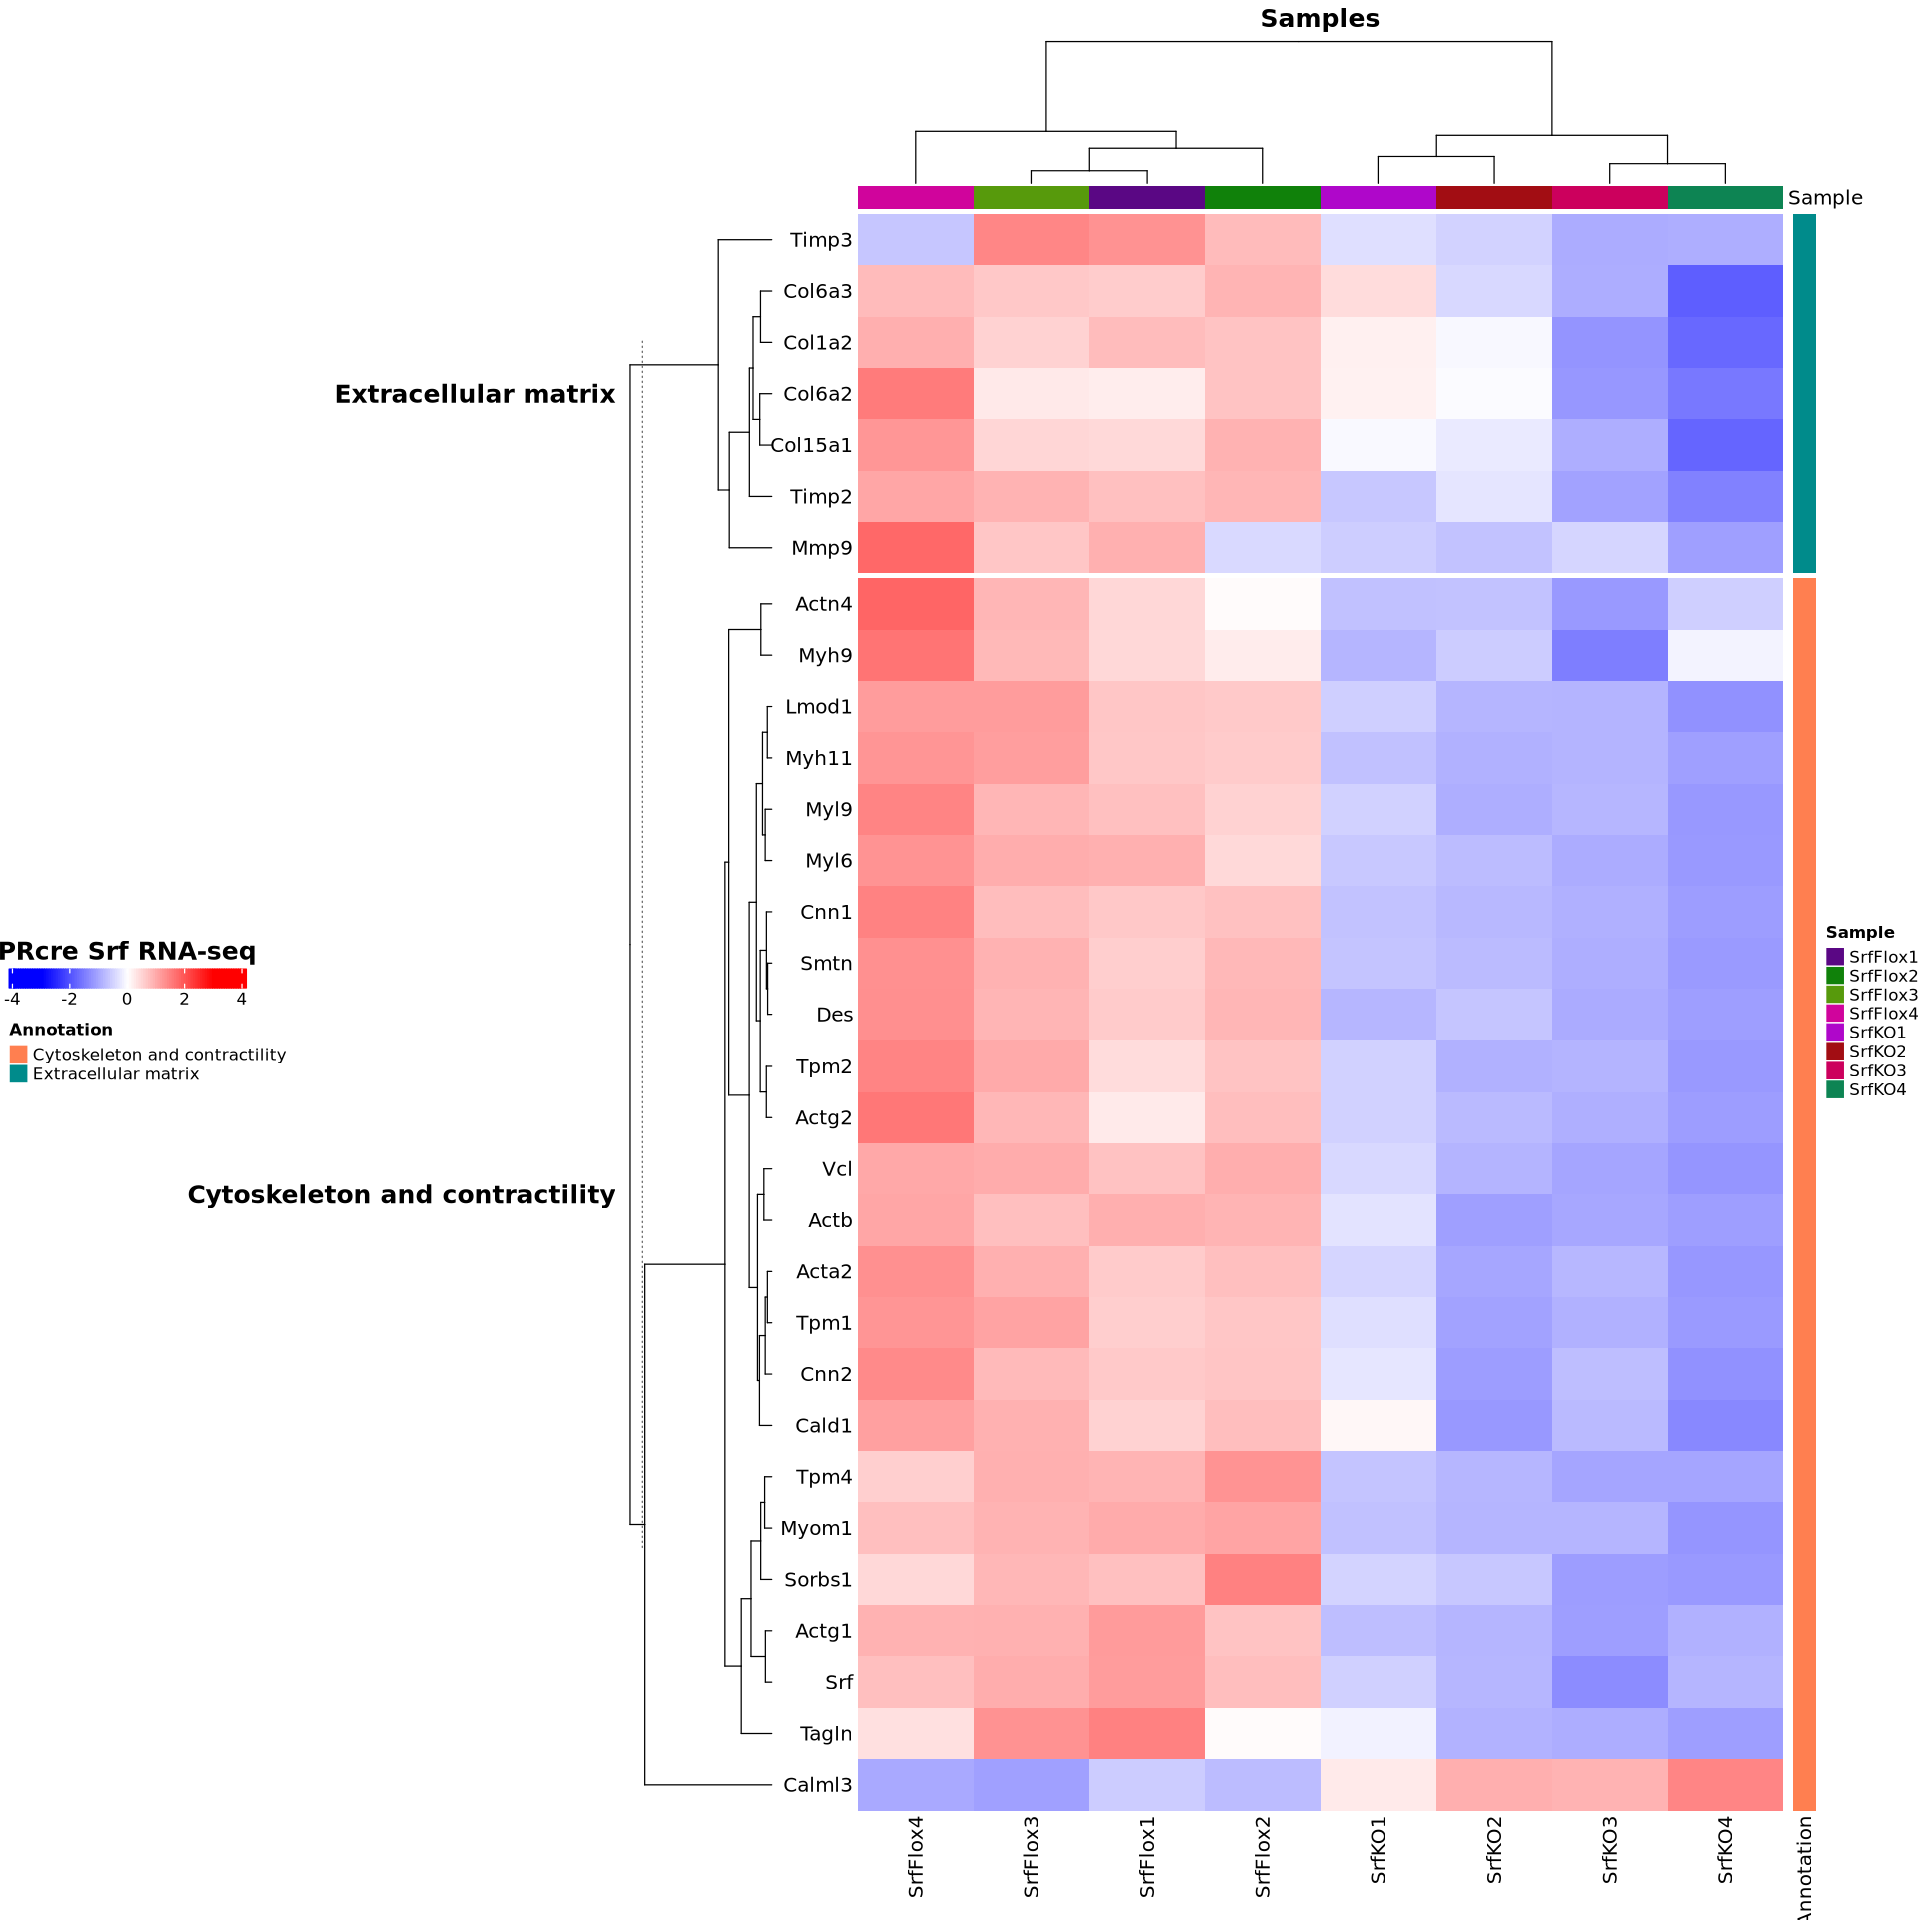

In [26]:
# Set heatmap parameters and draw

saved <- options(repr.plot.width = 16, repr.plot.height = 16) # Make the plots bigger from here on out, save old options

hmap <- Heatmap(heat,
        name="PRcre Srf RNA-seq",
        col=colorRamp2(myBreaks, myCol),
        heatmap_legend_param=list(color_bar="continuous", legend_direction="horizontal", legend_width=unit(5,"cm"), title_position="topcenter", title_gp=gpar(fontsize=15, fontface="bold")),

       #Split heatmap rows by annotation
        split=df$Annotation,

        #Row annotation configurations
        cluster_rows=TRUE,
        show_row_dend=TRUE,
        #row_title="Transcript", #overridden by 'split' it seems
        row_title_side="left",
        row_title_gp=gpar(fontsize=15, fontface="bold"),
        show_row_names=TRUE,
        row_names_side="left",
        row_title_rot=0,

        #Column annotation configuratiions
        cluster_columns=TRUE,
        show_column_dend=TRUE,
        column_title="Samples",
        column_title_side="top",
        column_title_gp=gpar(fontsize=15, fontface="bold"),
        column_title_rot=0,
        show_column_names=TRUE,

        #Dendrogram configurations: columns
        clustering_distance_columns=function(x) as.dist(1-cor(t(x))),
        clustering_method_columns="ward.D2",
        column_dend_height=unit(30,"mm"),

        #Dendrogram configurations: rows
        clustering_distance_rows="euclidean",
        clustering_method_rows="ward.D2",
        row_dend_width=unit(30,"mm"),

        #Annotations (row annotation must be added with 'draw' function, below)
        
        top_annotation=ColAnn)


draw(hmap + RowAnn, heatmap_legend_side="left", annotation_legend_side="right")

options(saved) # restore old settings

Warning message in order(as.numeric(gsub("column", "", colnames(heat)))):
“NAs introduced by coercion”


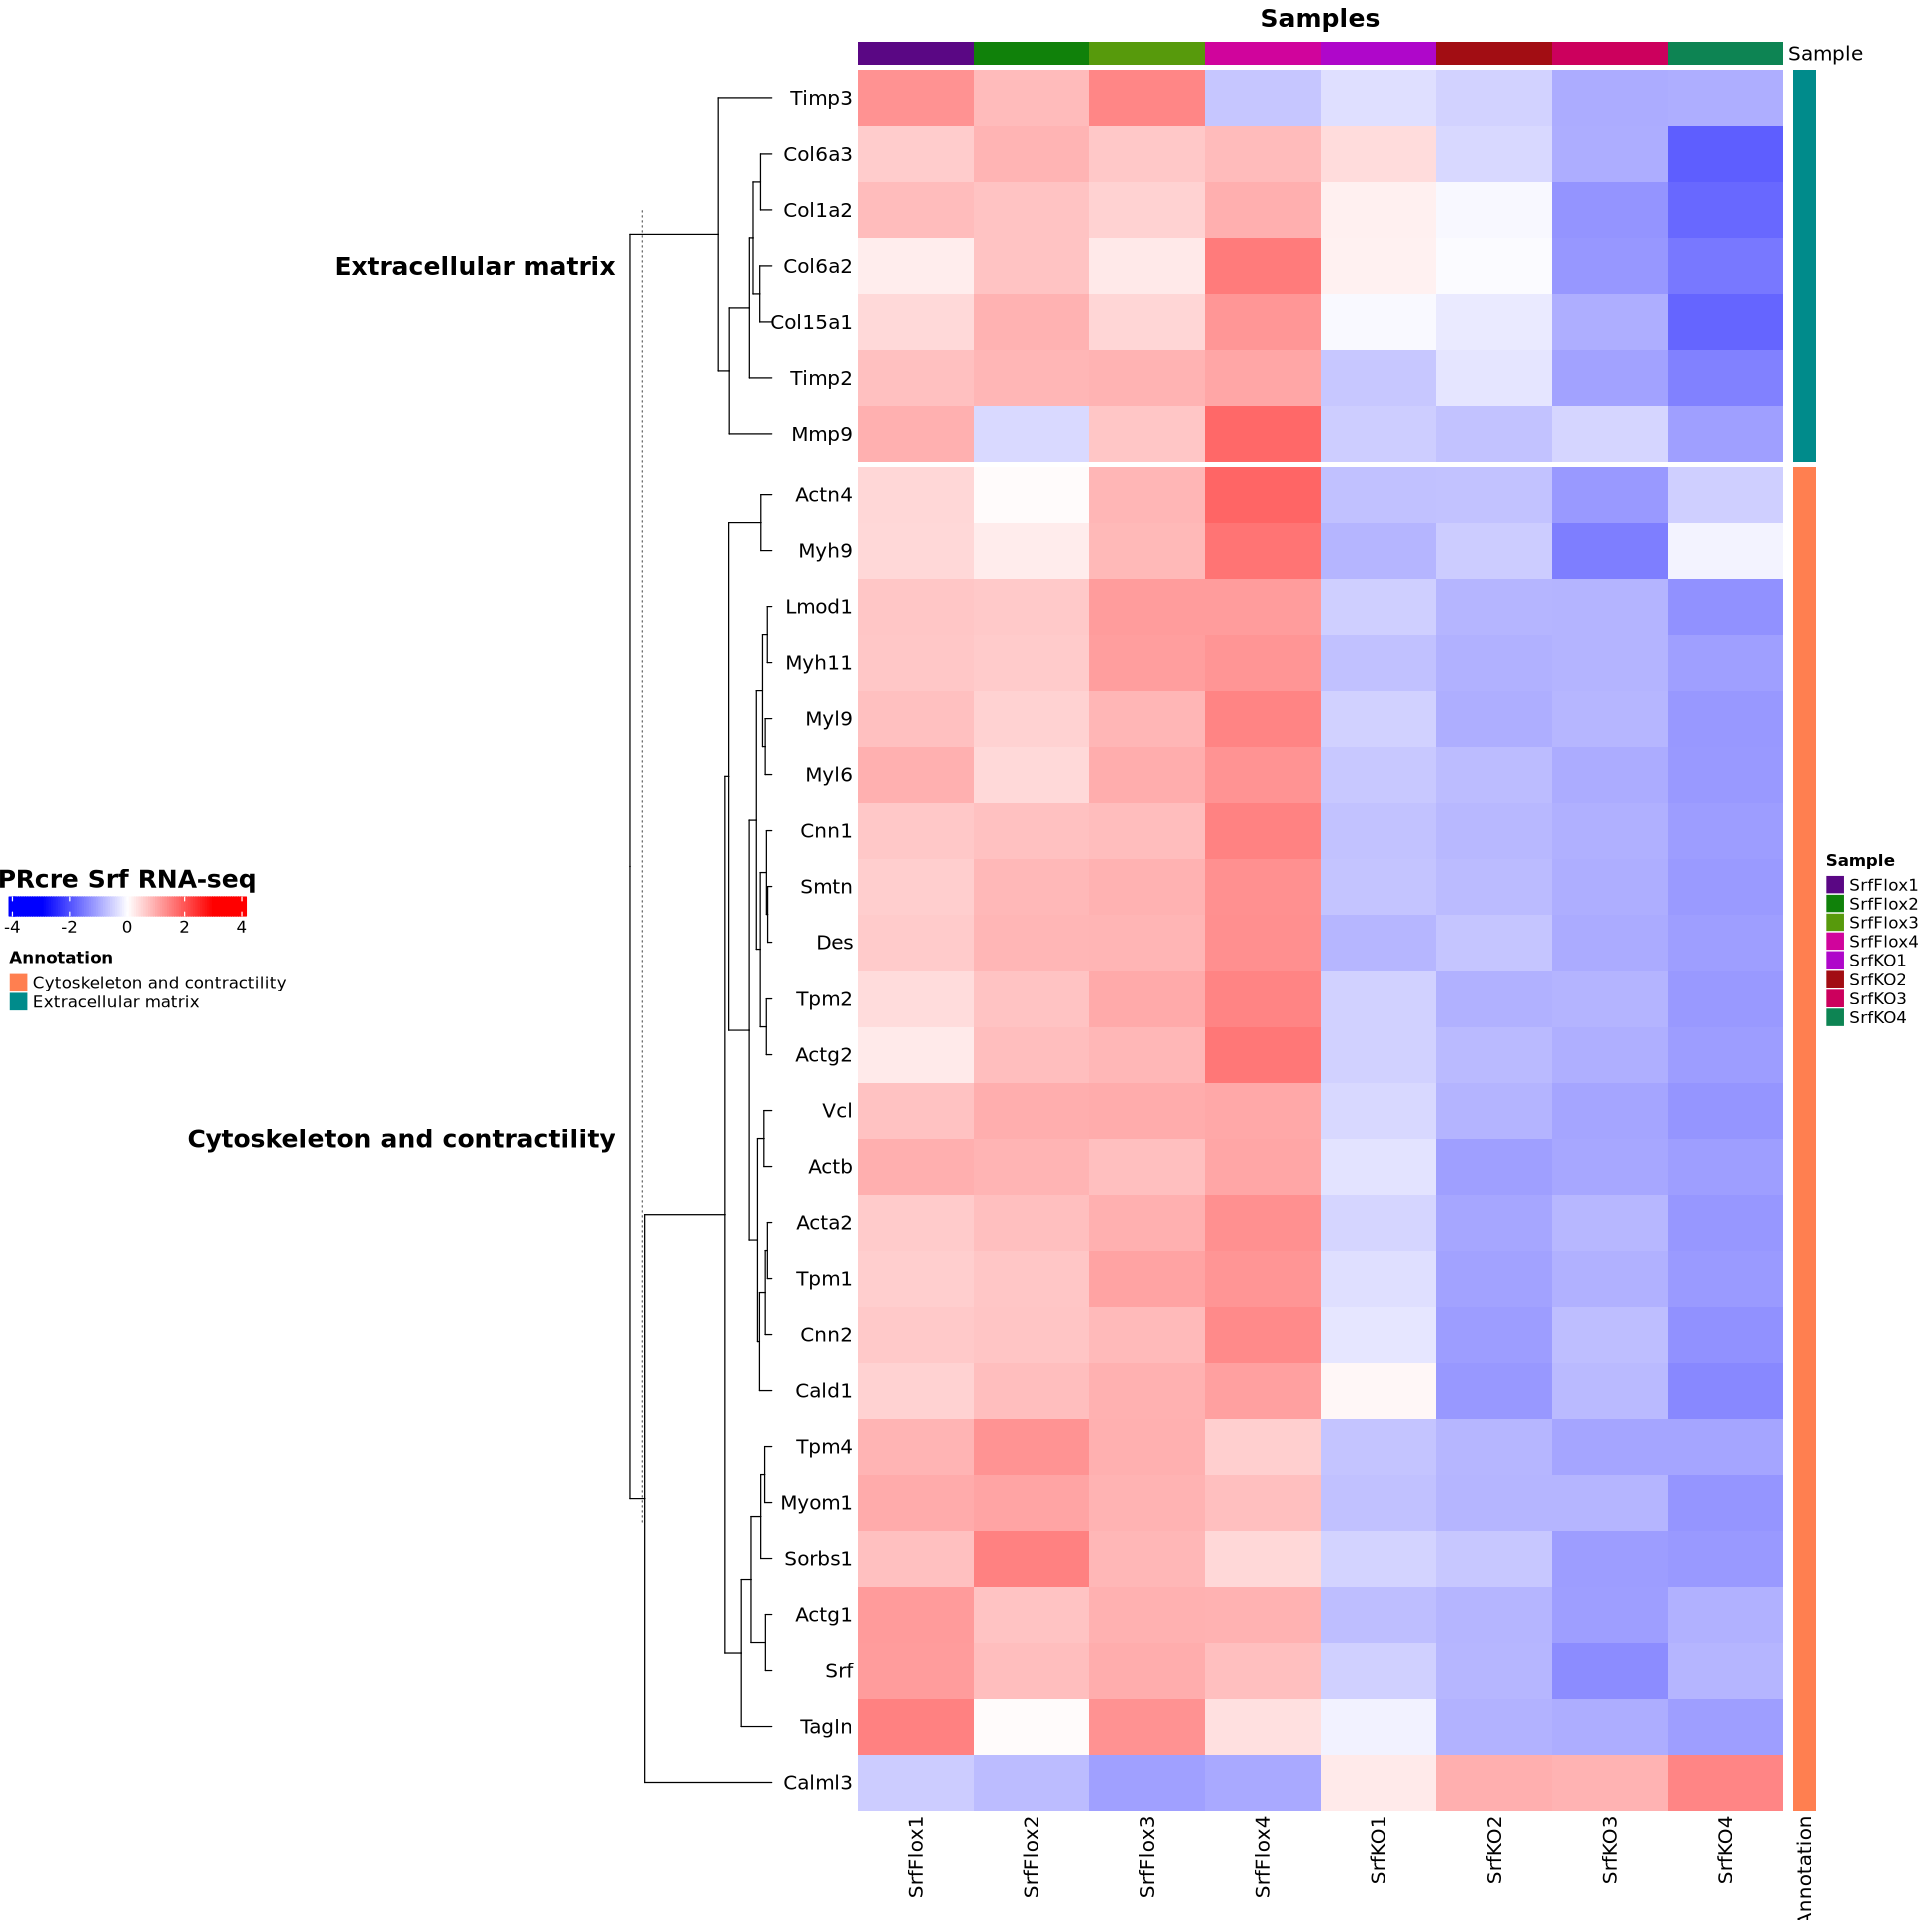

In [27]:
# Stop clustering samples

saved <- options(repr.plot.width = 16, repr.plot.height = 16) # Make the plots bigger from here on out, save old options

hmap <- Heatmap(heat,
        name="PRcre Srf RNA-seq",
        col=colorRamp2(myBreaks, myCol),
        heatmap_legend_param=list(color_bar="continuous", legend_direction="horizontal", legend_width=unit(5,"cm"), title_position="topcenter", title_gp=gpar(fontsize=15, fontface="bold")),

       #Split heatmap rows by annotation
        split=df$Annotation,

        #Row annotation configurations
        cluster_rows=TRUE,
        show_row_dend=TRUE,
        #row_title="Transcript", #overridden by 'split' it seems
        row_title_side="left",
        row_title_gp=gpar(fontsize=15, fontface="bold"),
        show_row_names=TRUE,
        row_names_side="left",
        row_title_rot=0,

        #Column annotation configuratiions
        cluster_columns=FALSE,
        show_column_dend=FALSE,
        column_title="Samples",
        column_title_side="top",
        column_title_gp=gpar(fontsize=15, fontface="bold"),
        column_title_rot=0,
        show_column_names=TRUE,

        #Keep column order instead of clustering
        column_order = order(as.numeric(gsub("column", "", colnames(heat)))),
                
        #Dendrogram configurations: rows
        clustering_distance_rows="euclidean",
        clustering_method_rows="ward.D2",
        row_dend_width=unit(30,"mm"),

        #Annotations (row annotation must be added with 'draw' function, below)
        
        top_annotation=ColAnn)


draw(hmap + RowAnn, heatmap_legend_side="left", annotation_legend_side="right")

options(saved) # restore old settings

In [28]:
# If you want to adjust the sample order but keep clustering turned off, change column order in the matrix
new_order <- c(4, 3, 1, 2, 5, 6, 7, 8)
heat <- heat[, new_order]
head(heat) # check our work

,SrfFlox4,SrfFlox3,SrfFlox1,SrfFlox2,SrfKO1,SrfKO2,SrfKO3,SrfKO4
Myh11,1.237565,1.1357395,0.6505914,0.6099073,-0.7156183,-0.9172950,-0.8822195,-1.118670
Cnn1,1.461327,0.7710400,0.6382676,0.7259708,-0.7055393,-0.8263343,-0.9241287,-1.140603
Actg2,1.589376,0.8427980,0.2391729,0.7576676,-0.5358622,-0.8106814,-0.9421940,-1.140276
Des,1.311314,0.8610673,0.6101935,0.8588085,-0.8593700,-0.6682597,-0.9859392,-1.127815
Tpm2,1.436392,0.9904577,0.4015667,0.6924698,-0.5400823,-0.9107845,-0.8748670,-1.195153
Acta2,1.308946,0.9221973,0.6098845,0.7454723,-0.4877536,-1.0432520,-0.8410441,-1.214451


Warning message in order(as.numeric(gsub("column", "", colnames(heat)))):
“NAs introduced by coercion”


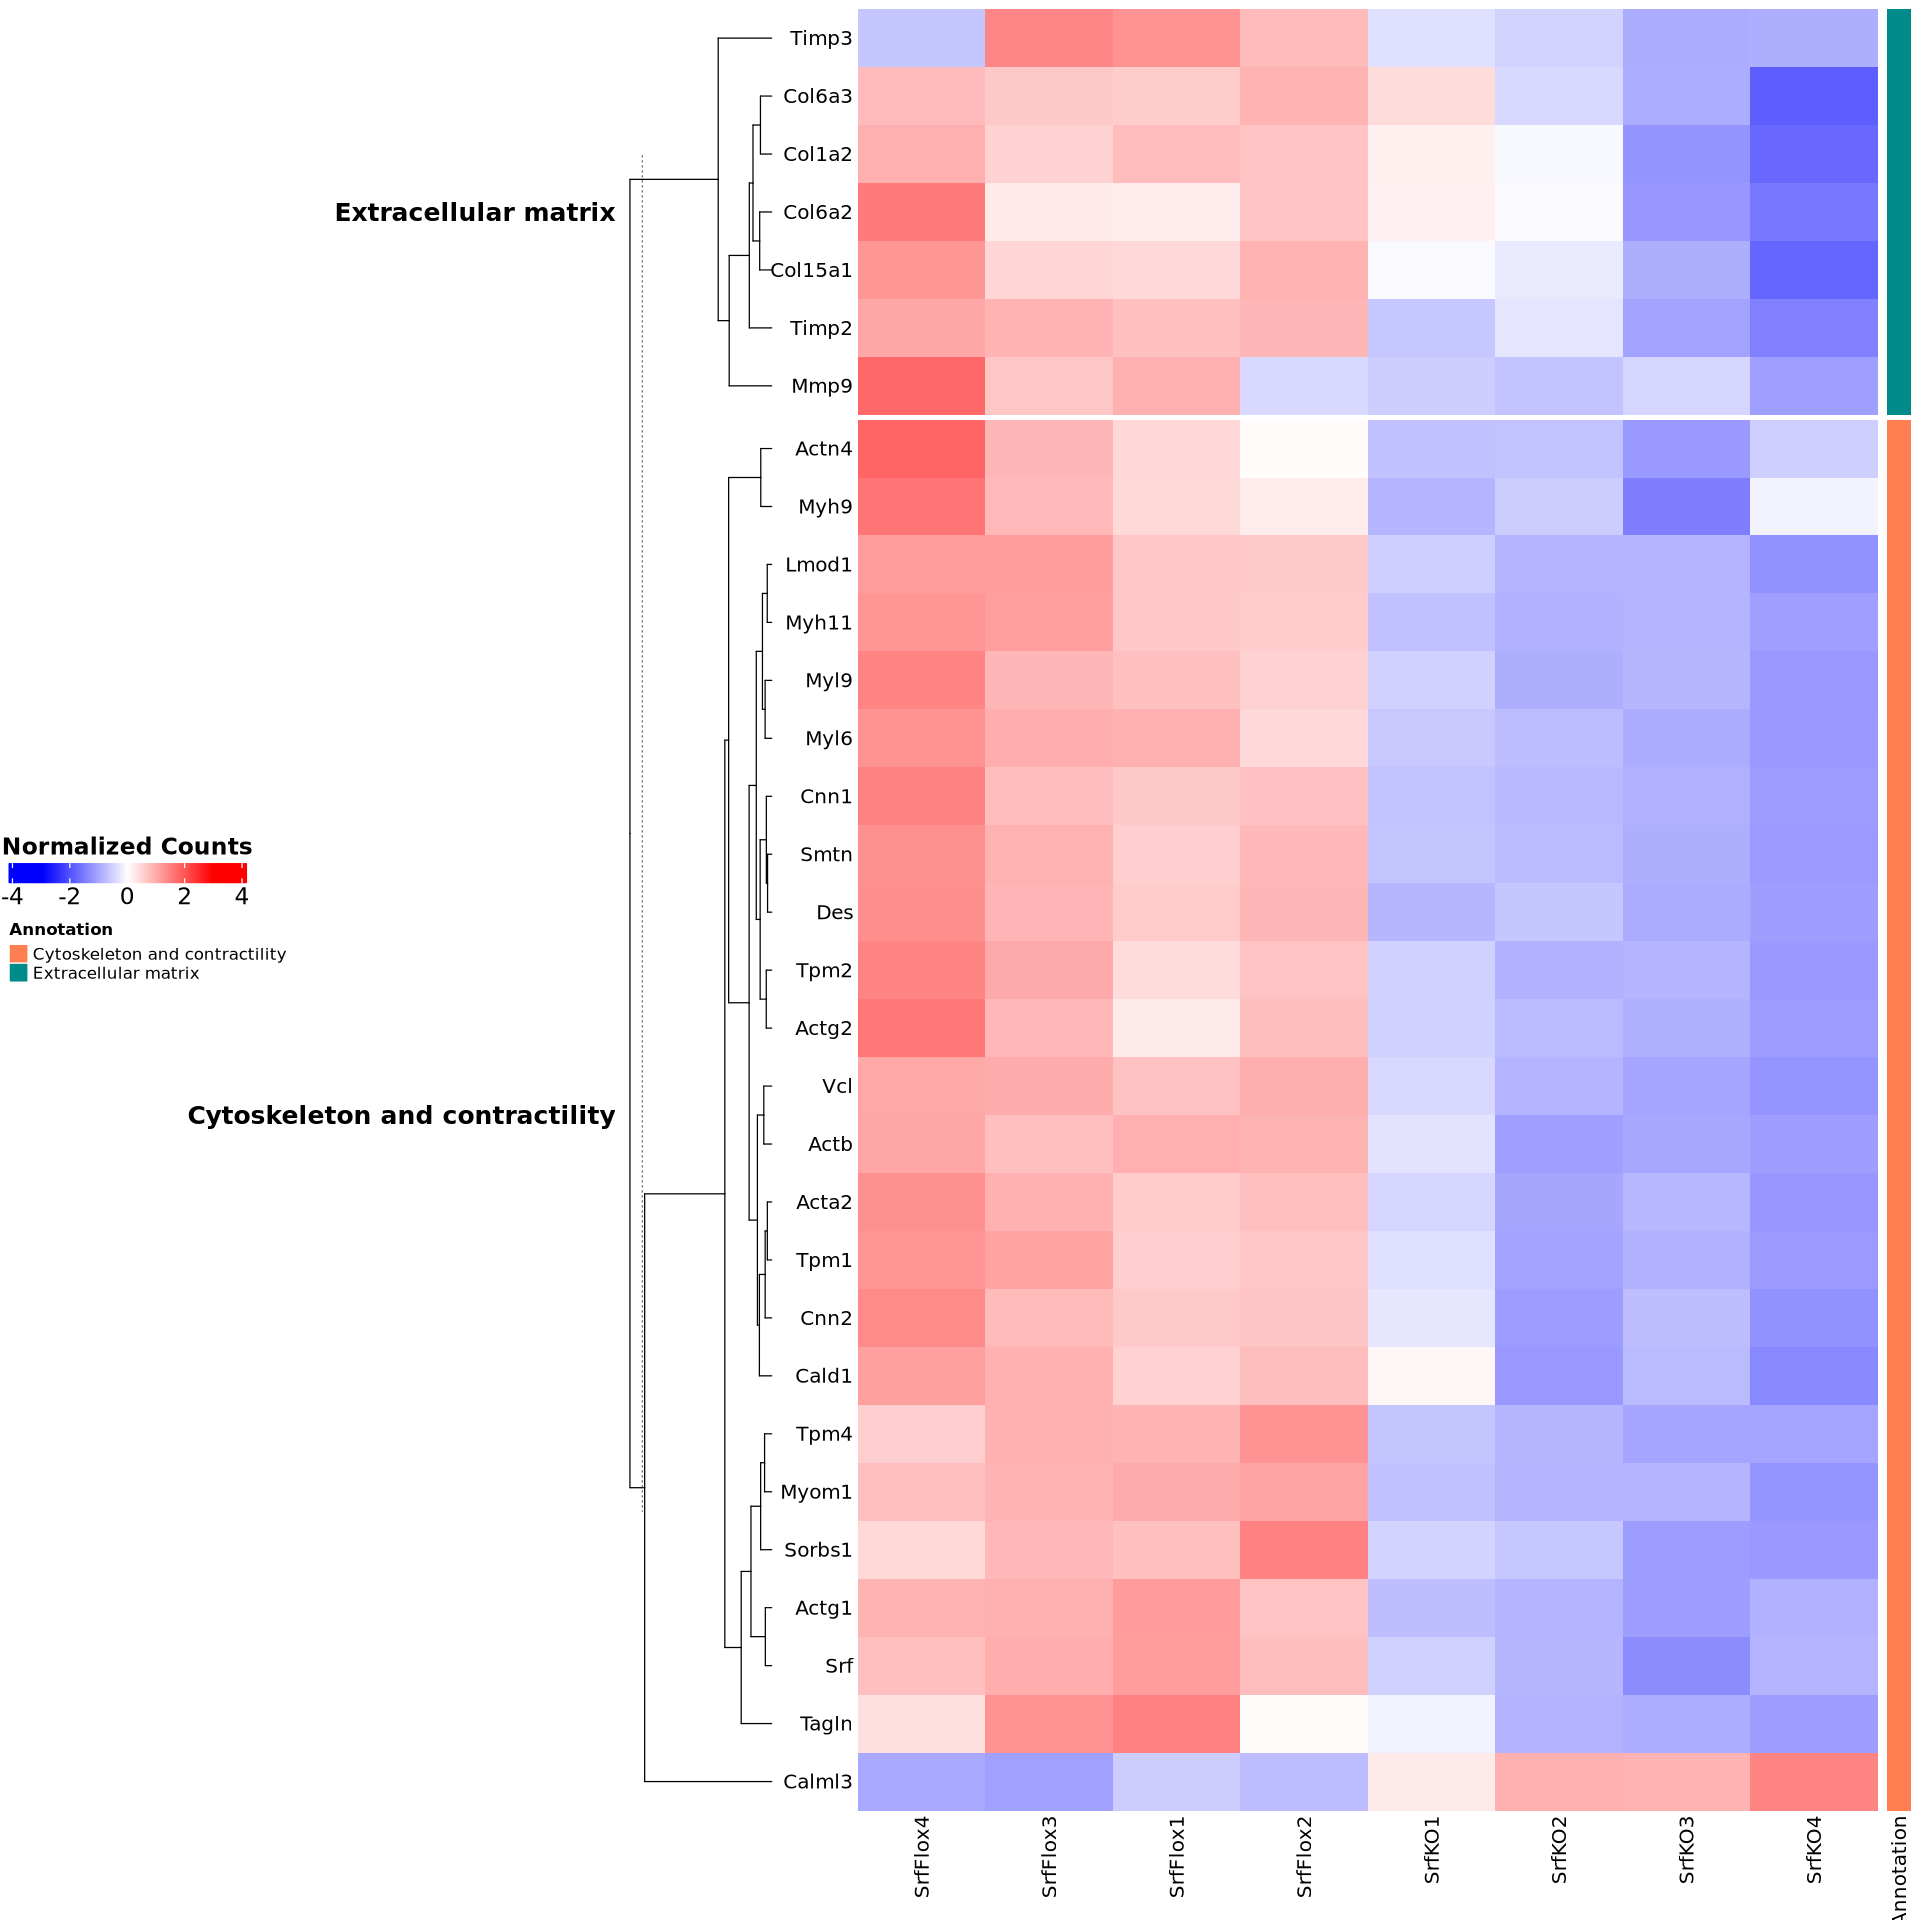

In [29]:
# Now plot again without sample annotation at the top

saved <- options(repr.plot.width = 16, repr.plot.height = 16) # Make the plots bigger from here on out, save old options

#Set annotation parameters

RowAnn <- data.frame(df$Annotation)
  colnames(RowAnn) <- c("Annotation")
  colours <- list("Annotation"=c("Cytoskeleton and contractility"="coral", "Extracellular matrix"="darkcyan"))
  RowAnn <- HeatmapAnnotation(df=RowAnn, col=colours, which="row")

myBreaks <- seq(-3, 3, length.out=100)
myCol <- colorRampPalette(c("blue", "white", "red"))(100)

#Set heatmap parameters
hmap <- Heatmap(heat,
        name="Normalized Counts",
        col=colorRamp2(myBreaks, myCol),
        heatmap_legend_param=list(color_bar="continuous", 
            legend_direction="horizontal", 
            legend_width=unit(5,"cm"), 
            title_position="topcenter", 
            title_gp=gpar(fontsize=14, fontface="bold"),
            labels_gp=gpar(fontsize=14)),

       #Split heatmap rows by annotation
        split=df$Annotation,

        #Row annotation configurations
        cluster_rows=TRUE,
        show_row_dend=TRUE,
        #row_title="Transcript", #overridden by 'split' it seems
        row_title_side="left",
        row_title_gp=gpar(fontsize=15, fontface="bold"),
        show_row_names=TRUE,
        row_names_side="left",
        row_title_rot=0,

        #Column annotation configuratiions
        cluster_columns=FALSE,
        show_column_dend=FALSE,
        column_title="", # blank the title and it won't show up
        column_title_side="top",
        column_title_gp=gpar(fontsize=15, fontface="bold"),
        column_title_rot=0,
        show_column_names=TRUE,

        #Keep column order instead of clustering
        column_order = order(as.numeric(gsub("column", "", colnames(heat)))),
                
        #Dendrogram configurations: rows
        clustering_distance_rows="euclidean",
        clustering_method_rows="ward.D2",
        row_dend_width=unit(30,"mm"))

        #Annotations (row annotation must be added with 'draw' function, below)
        
        # top_annotation=ColAnn) comment out the top annotation


draw(hmap + RowAnn, heatmap_legend_side="left", annotation_legend_side="right")

options(saved) # restore old settings

Warning message in order(as.numeric(gsub("column", "", colnames(heat)))):
“NAs introduced by coercion”


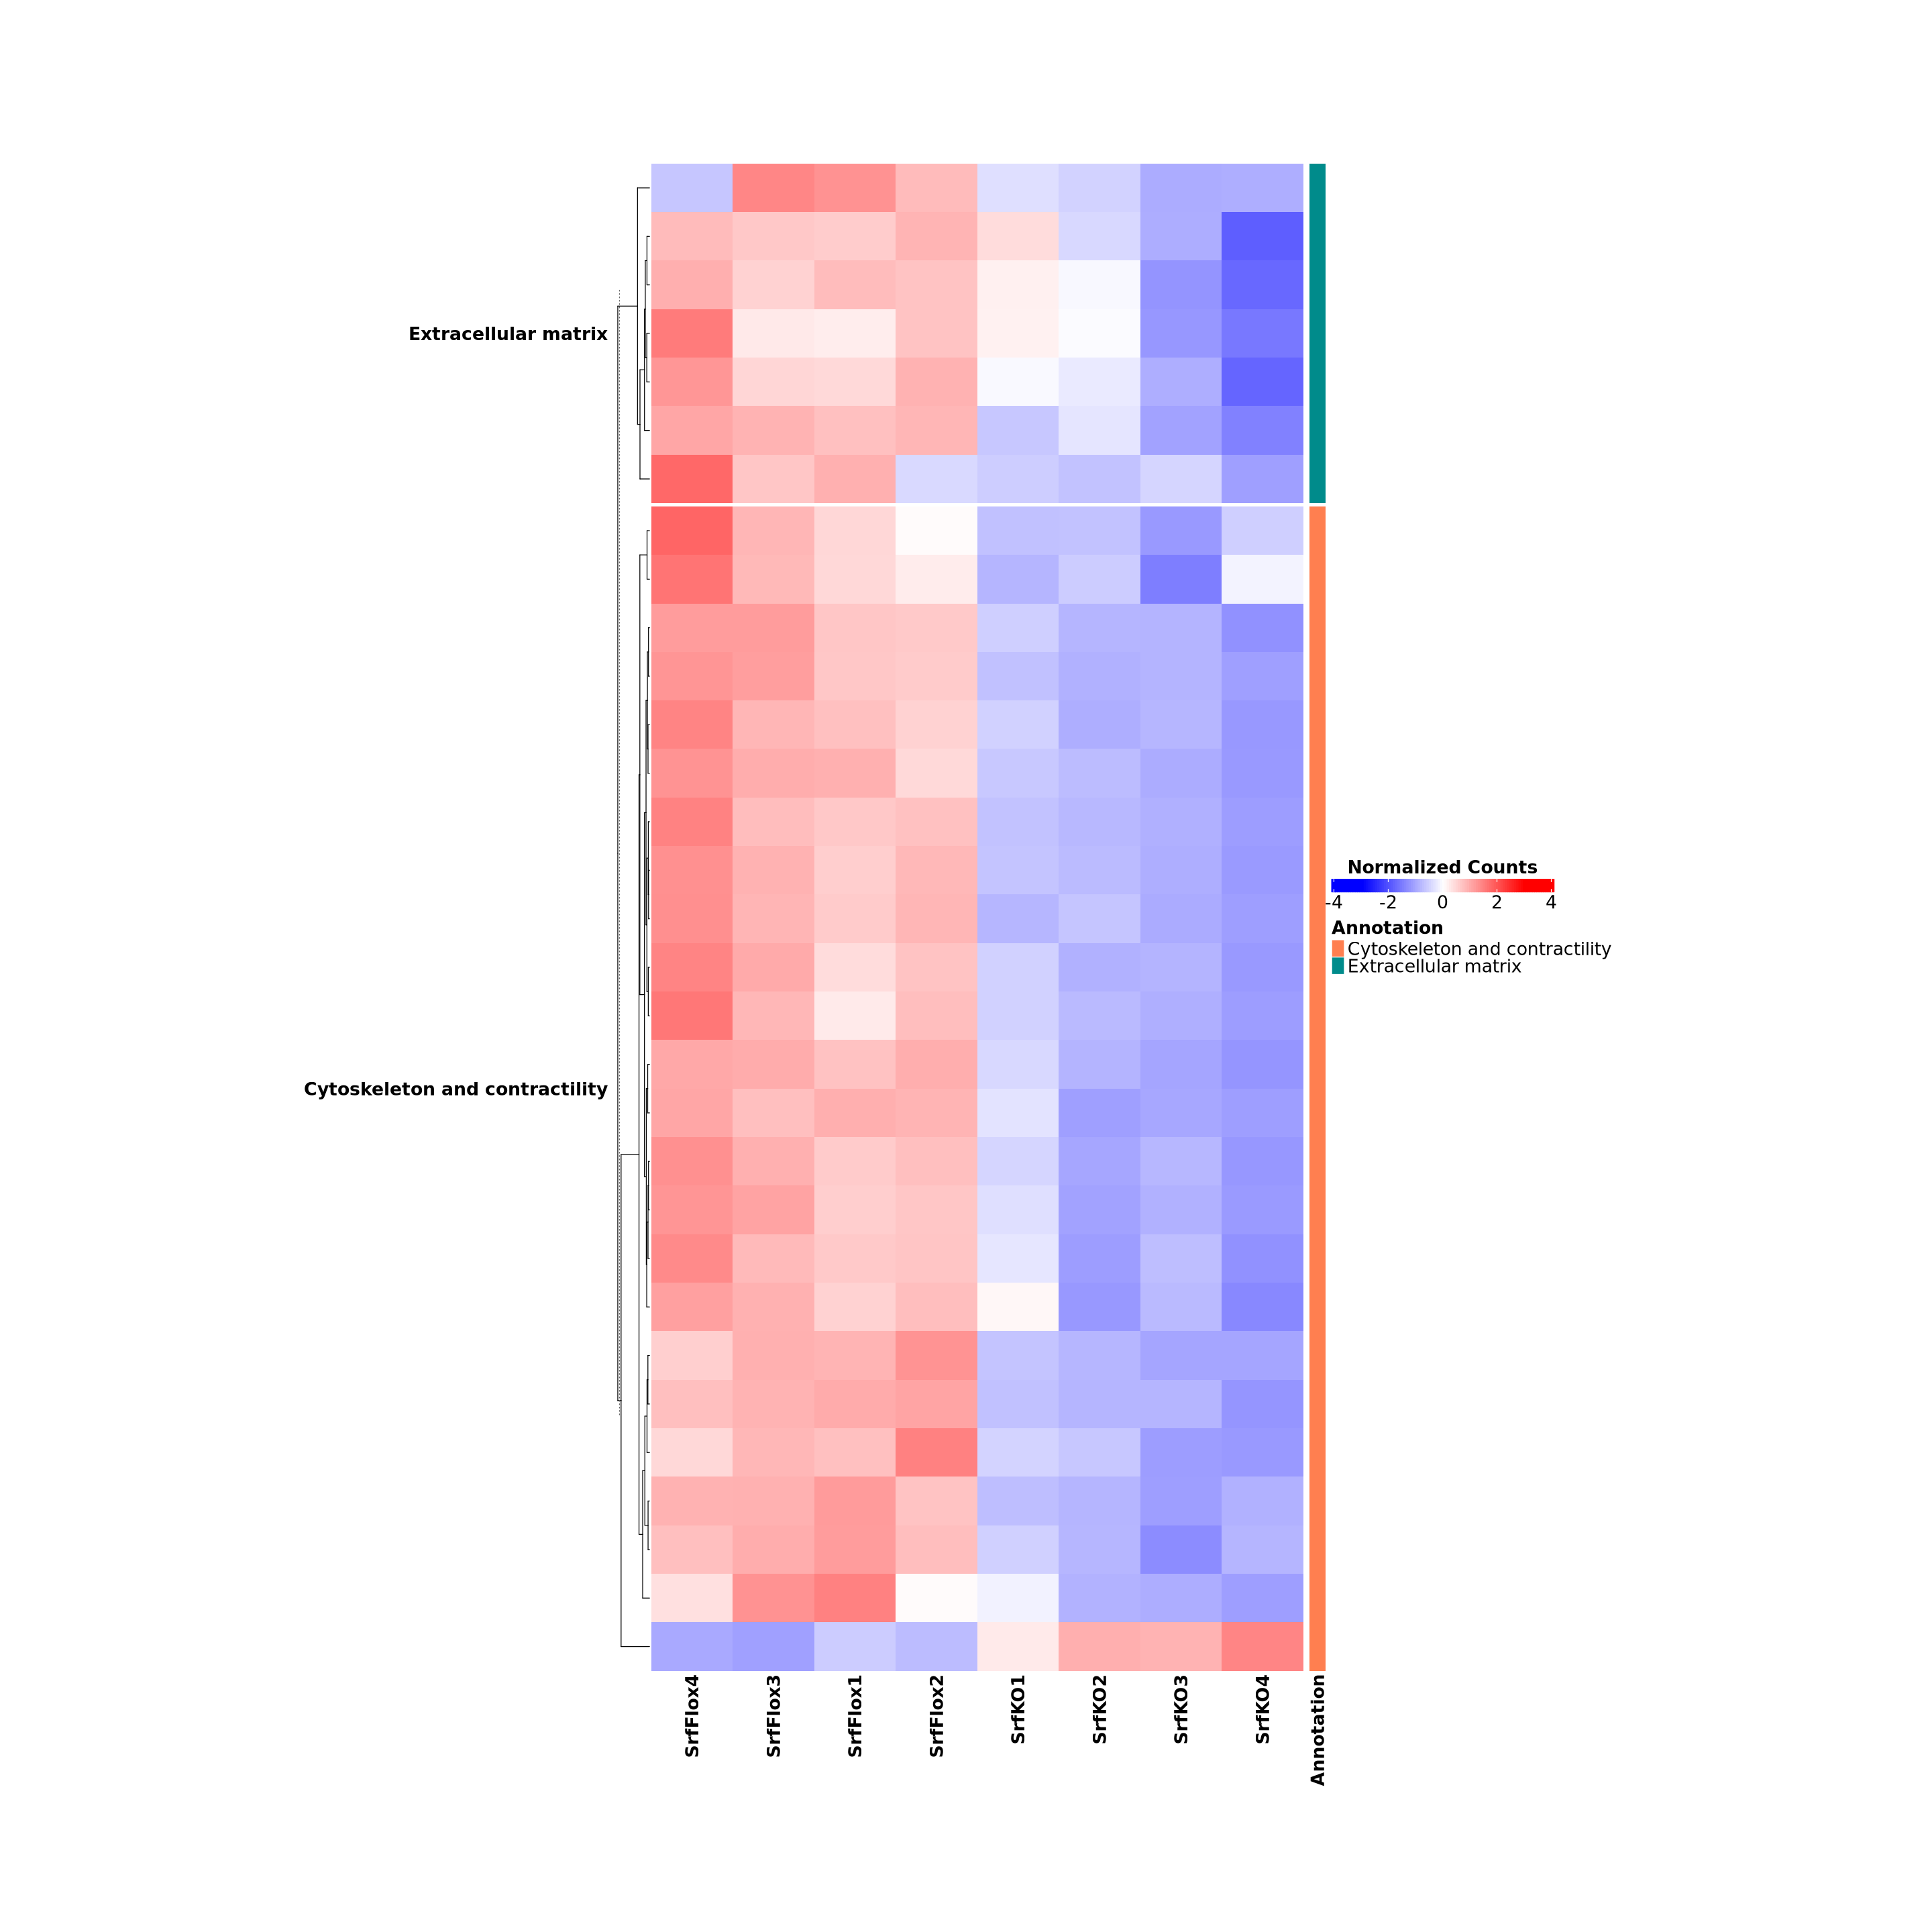

In [30]:
# Move legend to the right side

saved <- options(repr.plot.width = 24, repr.plot.height = 24) # Make the plots bigger from here on out, save old options

set.seed(123)
#Set annotation parameters

RowAnn <- data.frame(df$Annotation)
  colnames(RowAnn) <- c("Annotation")
  colours <- list("Annotation"=c("Cytoskeleton and contractility"="coral", "Extracellular matrix"="darkcyan"))
  RowAnn <- HeatmapAnnotation(df=RowAnn, 
                              col=colours,
                              annotation_name_gp = gpar(fontsize = 16, fontface = "bold"),
                              which="row",
                              annotation_legend_param = list(
                                                title_gp = gpar(fontsize = 16, fontface = "bold"), 
                                                labels_gp = gpar(fontsize = 16)))

myBreaks <- seq(-3, 3, length.out=100)
myCol <- colorRampPalette(c("blue", "white", "red"))(100)

#Set heatmap parameters
hmap <- Heatmap(heat,
        name="Normalized Counts",
        col=colorRamp2(myBreaks, myCol),
        heatmap_width = unit(30,"cm"),
        heatmap_height = unit(50,"cm"),
        column_names_gp = gpar(fontsize = 16, fontface="bold"),
        heatmap_legend_param=list(color_bar="continuous", 
            legend_direction="horizontal", 
            legend_width=unit(7,"cm"), 
            title_position="topcenter", 
            title_gp=gpar(fontsize=16, fontface="bold"),
            labels_gp=gpar(fontsize=16)),

        #Keep column order instead of clustering
        column_order = order(as.numeric(gsub("column", "", colnames(heat)))),
                
        #Split heatmap rows by annotation
        split=df$Annotation,

        #Row annotation configurations
        cluster_rows=TRUE,
        show_row_dend=TRUE,
        row_title_side="left",
        row_title_gp=gpar(fontsize=16, fontface="bold"),
        show_row_names=FALSE,
        row_names_side="left",
        row_title_rot=0,

        #Column annotation configuratiions
        cluster_columns=FALSE,
        show_column_dend=FALSE,
        column_title="",
        column_title_side="top",
        column_title_gp=gpar(fontsize=15, fontface="bold"),
        column_title_rot=0,
        show_column_names=TRUE,

        
                
        #Dendrogram configurations: rows
        clustering_distance_rows="euclidean",
        clustering_method_rows="ward.D2",
        row_dend_width=unit(10,"mm"))

        #Annotations (row annotation must be added with 'draw' function, below)
        


draw(hmap + RowAnn, heatmap_legend_side="right", annotation_legend_side="right")

options(saved) # restore old settings

Warning message in order(as.numeric(gsub("column", "", colnames(heat)))):
“NAs introduced by coercion”


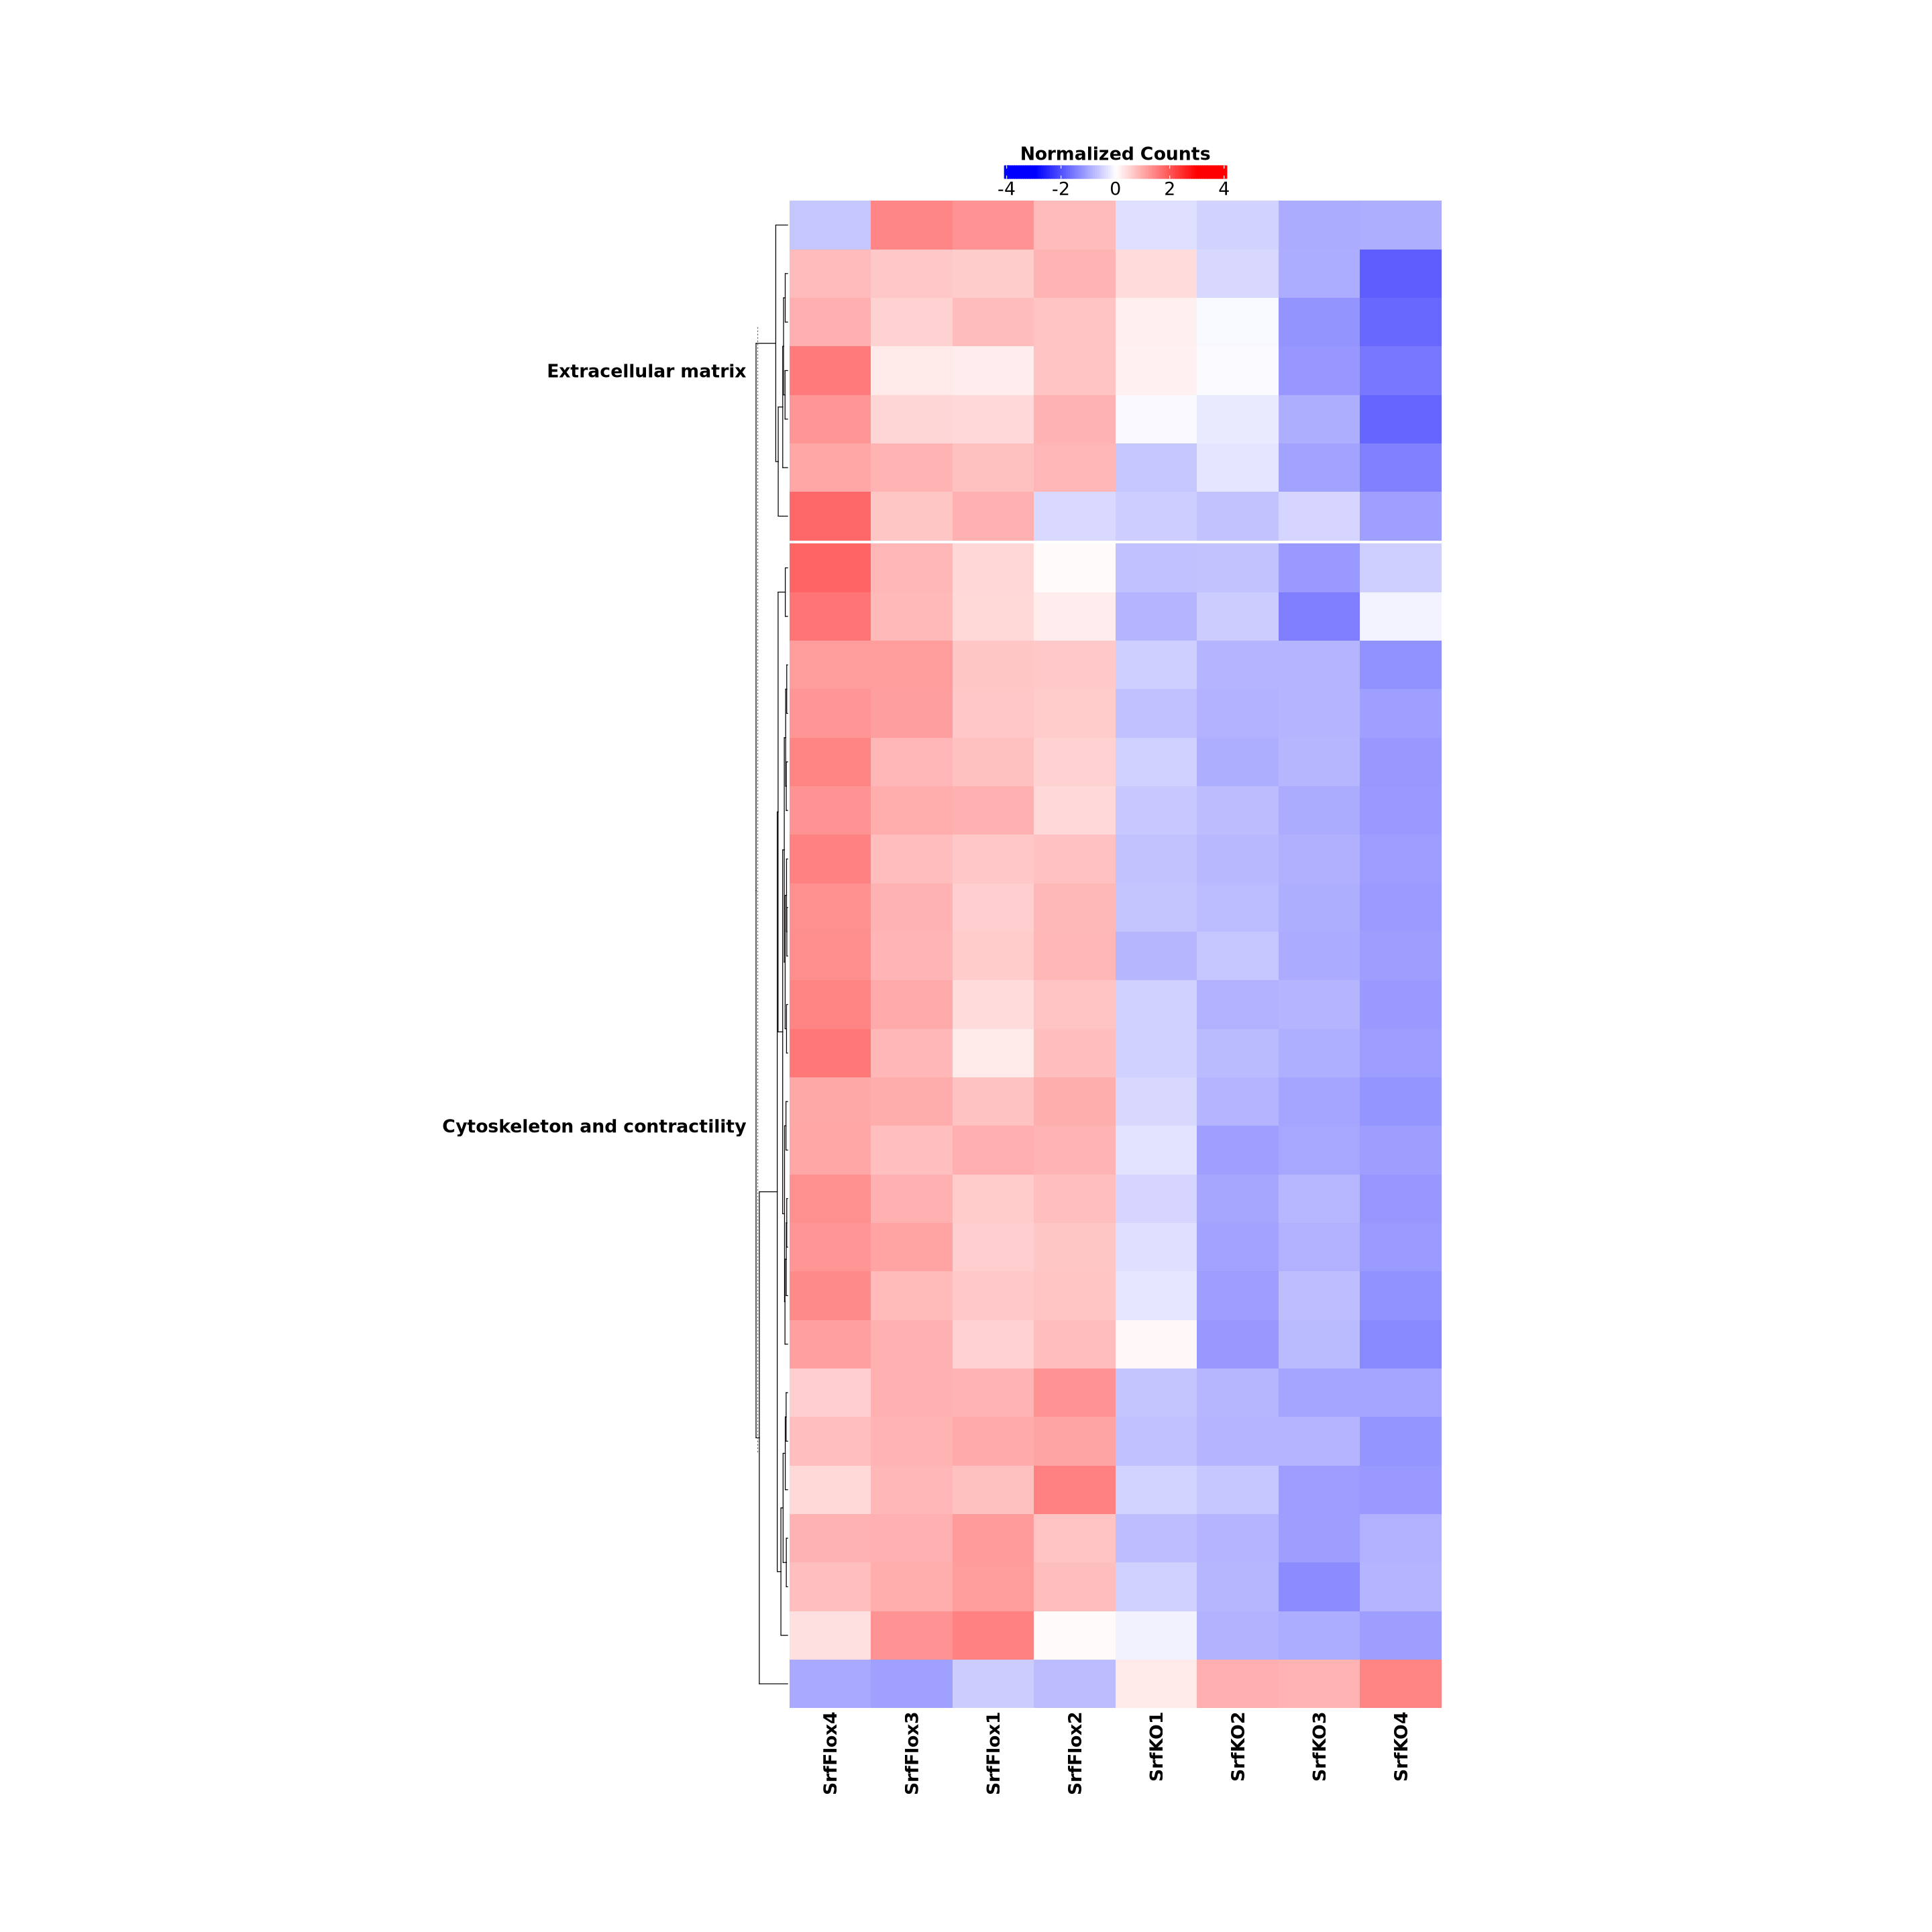

In [31]:
# draw again without right side annotation (just left off the final draw function)

saved <- options(repr.plot.width = 24, repr.plot.height = 24) # Make the plots bigger from here on out, save old options

set.seed(123)
#Set annotation parameters

RowAnn <- data.frame(df$Annotation)
  colnames(RowAnn) <- c("Annotation")
  colours <- list("Annotation"=c("Cytoskeleton and contractility"="coral", "Extracellular matrix"="darkcyan"))
  RowAnn <- HeatmapAnnotation(df=RowAnn, 
                              col=colours,
                              annotation_name_gp = gpar(fontsize = 16, fontface = "bold"),
                              which="row",
                              annotation_legend_param = list(
                                                title_gp = gpar(fontsize = 16, fontface = "bold"), 
                                                labels_gp = gpar(fontsize = 16)))

myBreaks <- seq(-3, 3, length.out=100)
myCol <- colorRampPalette(c("blue", "white", "red"))(100)

#Set heatmap parameters
hmap <- Heatmap(heat,
        name="Normalized Counts",
        col=colorRamp2(myBreaks, myCol),
        heatmap_width = unit(30,"cm"),
        heatmap_height = unit(50,"cm"),
        column_names_gp = gpar(fontsize = 16, fontface="bold"),
        heatmap_legend_param=list(color_bar="continuous", 
            legend_direction="horizontal", 
            legend_width=unit(7,"cm"), 
            title_position="topcenter", 
            title_gp=gpar(fontsize=16, fontface="bold"),
            labels_gp=gpar(fontsize=16)),

        #Keep column order instead of clustering
        column_order = order(as.numeric(gsub("column", "", colnames(heat)))),
                
        #Split heatmap rows by annotation
        split=df$Annotation,

        #Row annotation configurations
        cluster_rows=TRUE,
        show_row_dend=TRUE,
        row_title_side="left",
        row_title_gp=gpar(fontsize=16, fontface="bold"),
        show_row_names=FALSE,
        row_names_side="left",
        row_title_rot=0,

        #Column annotation configuratiions
        cluster_columns=FALSE,
        show_column_dend=FALSE,
        column_title="",
        column_title_side="top",
        column_title_gp=gpar(fontsize=15, fontface="bold"),
        column_title_rot=0,
        show_column_names=TRUE,

        
                
        #Dendrogram configurations: rows
        clustering_distance_rows="euclidean",
        clustering_method_rows="ward.D2",
        row_dend_width=unit(10,"mm"))

        #Annotations (row annotation must be added with 'draw' function, below)
        


draw(hmap, heatmap_legend_side="top")

options(saved) # restore old settings

Warning message in order(as.numeric(gsub("column", "", colnames(heat)))):
“NAs introduced by coercion”


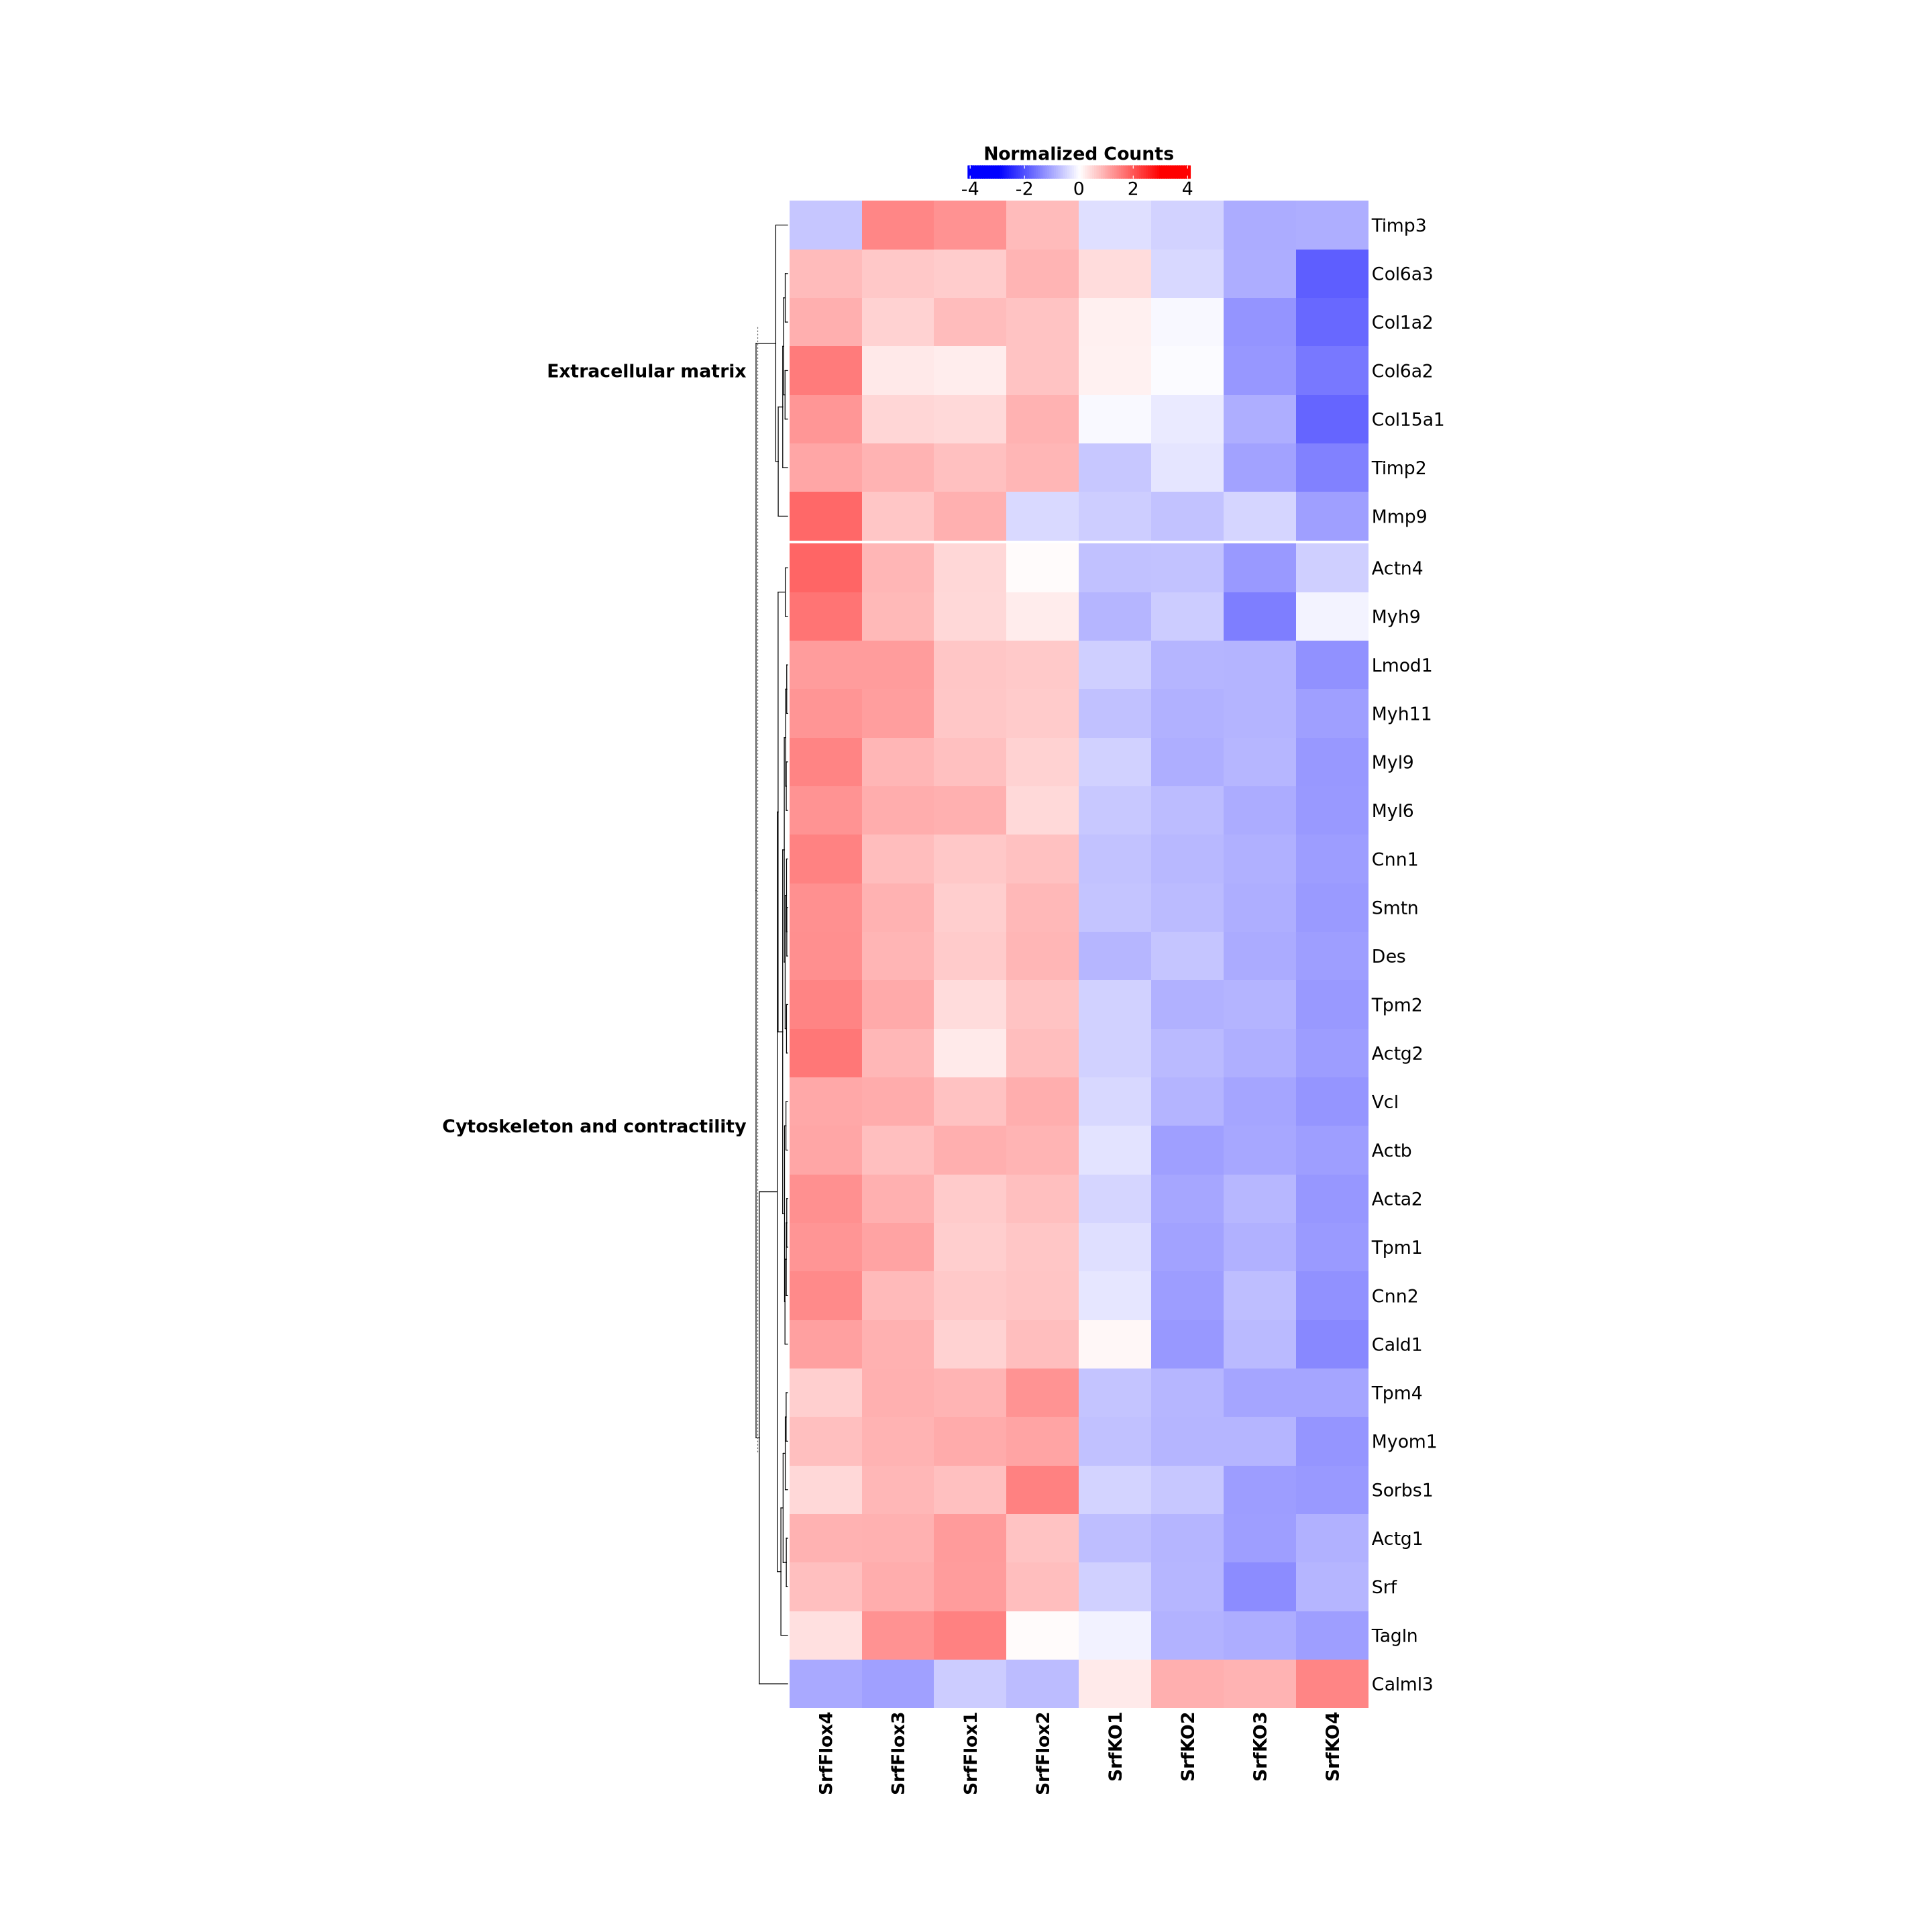

In [57]:
# draw again without right side annotation, adding row titles

saved <- options(repr.plot.width = 24, repr.plot.height = 24) # Make the plots bigger from here on out, save old options

set.seed(123)
#Set annotation parameters

RowAnn <- data.frame(df$Annotation)
  colnames(RowAnn) <- c("Annotation")
  colours <- list("Annotation"=c("Cytoskeleton and contractility"="coral", "Extracellular matrix"="darkcyan"))
  RowAnn <- HeatmapAnnotation(df=RowAnn, 
                              col=colours,
                              annotation_name_gp = gpar(fontsize = 16, fontface = "bold"),
                              which="row",
                              annotation_legend_param = list(
                                                title_gp = gpar(fontsize = 16, fontface = "bold"), 
                                                labels_gp = gpar(fontsize = 16)))

myBreaks <- seq(-3, 3, length.out=100)
myCol <- colorRampPalette(c("blue", "white", "red"))(100)

#Set heatmap parameters
hmap <- Heatmap(heat,
        name="Normalized Counts",
        col=colorRamp2(myBreaks, myCol),
        heatmap_width = unit(30,"cm"),
        heatmap_height = unit(50,"cm"),
        column_names_gp = gpar(fontsize = 16, fontface="bold"),
        heatmap_legend_param=list(color_bar="continuous", 
            legend_direction="horizontal", 
            legend_width=unit(7,"cm"), 
            title_position="topcenter", 
            title_gp=gpar(fontsize=16, fontface="bold"),
            labels_gp=gpar(fontsize=16)),

        #Keep column order instead of clustering
        column_order = order(as.numeric(gsub("column", "", colnames(heat)))),
                
        #Split heatmap rows by annotation
        split=df$Annotation,

        #Row annotation configurations
        cluster_rows=TRUE,
        show_row_dend=TRUE,
        row_title_side="left",
        row_title_gp=gpar(fontsize=16, fontface="bold"),
        show_row_names=TRUE,
        row_names_side="right",
        row_names_gp=gpar(fontsize=16),
        row_names_rot=0,
        row_title_rot=0,

        #Column annotation configuratiions
        cluster_columns=FALSE,
        show_column_dend=FALSE,
        column_title="",
        column_title_side="top",
        column_title_gp=gpar(fontsize=15, fontface="bold"),
        column_title_rot=0,
        show_column_names=TRUE,

        
                
        #Dendrogram configurations: rows
        clustering_distance_rows="euclidean",
        clustering_method_rows="ward.D2",
        row_dend_width=unit(10,"mm"))

        #Annotations (row annotation must be added with 'draw' function, below)
        


draw(hmap, heatmap_legend_side="top")

options(saved) # restore old settings

Warning message in order(as.numeric(gsub("column", "", colnames(heat)))):
“NAs introduced by coercion”


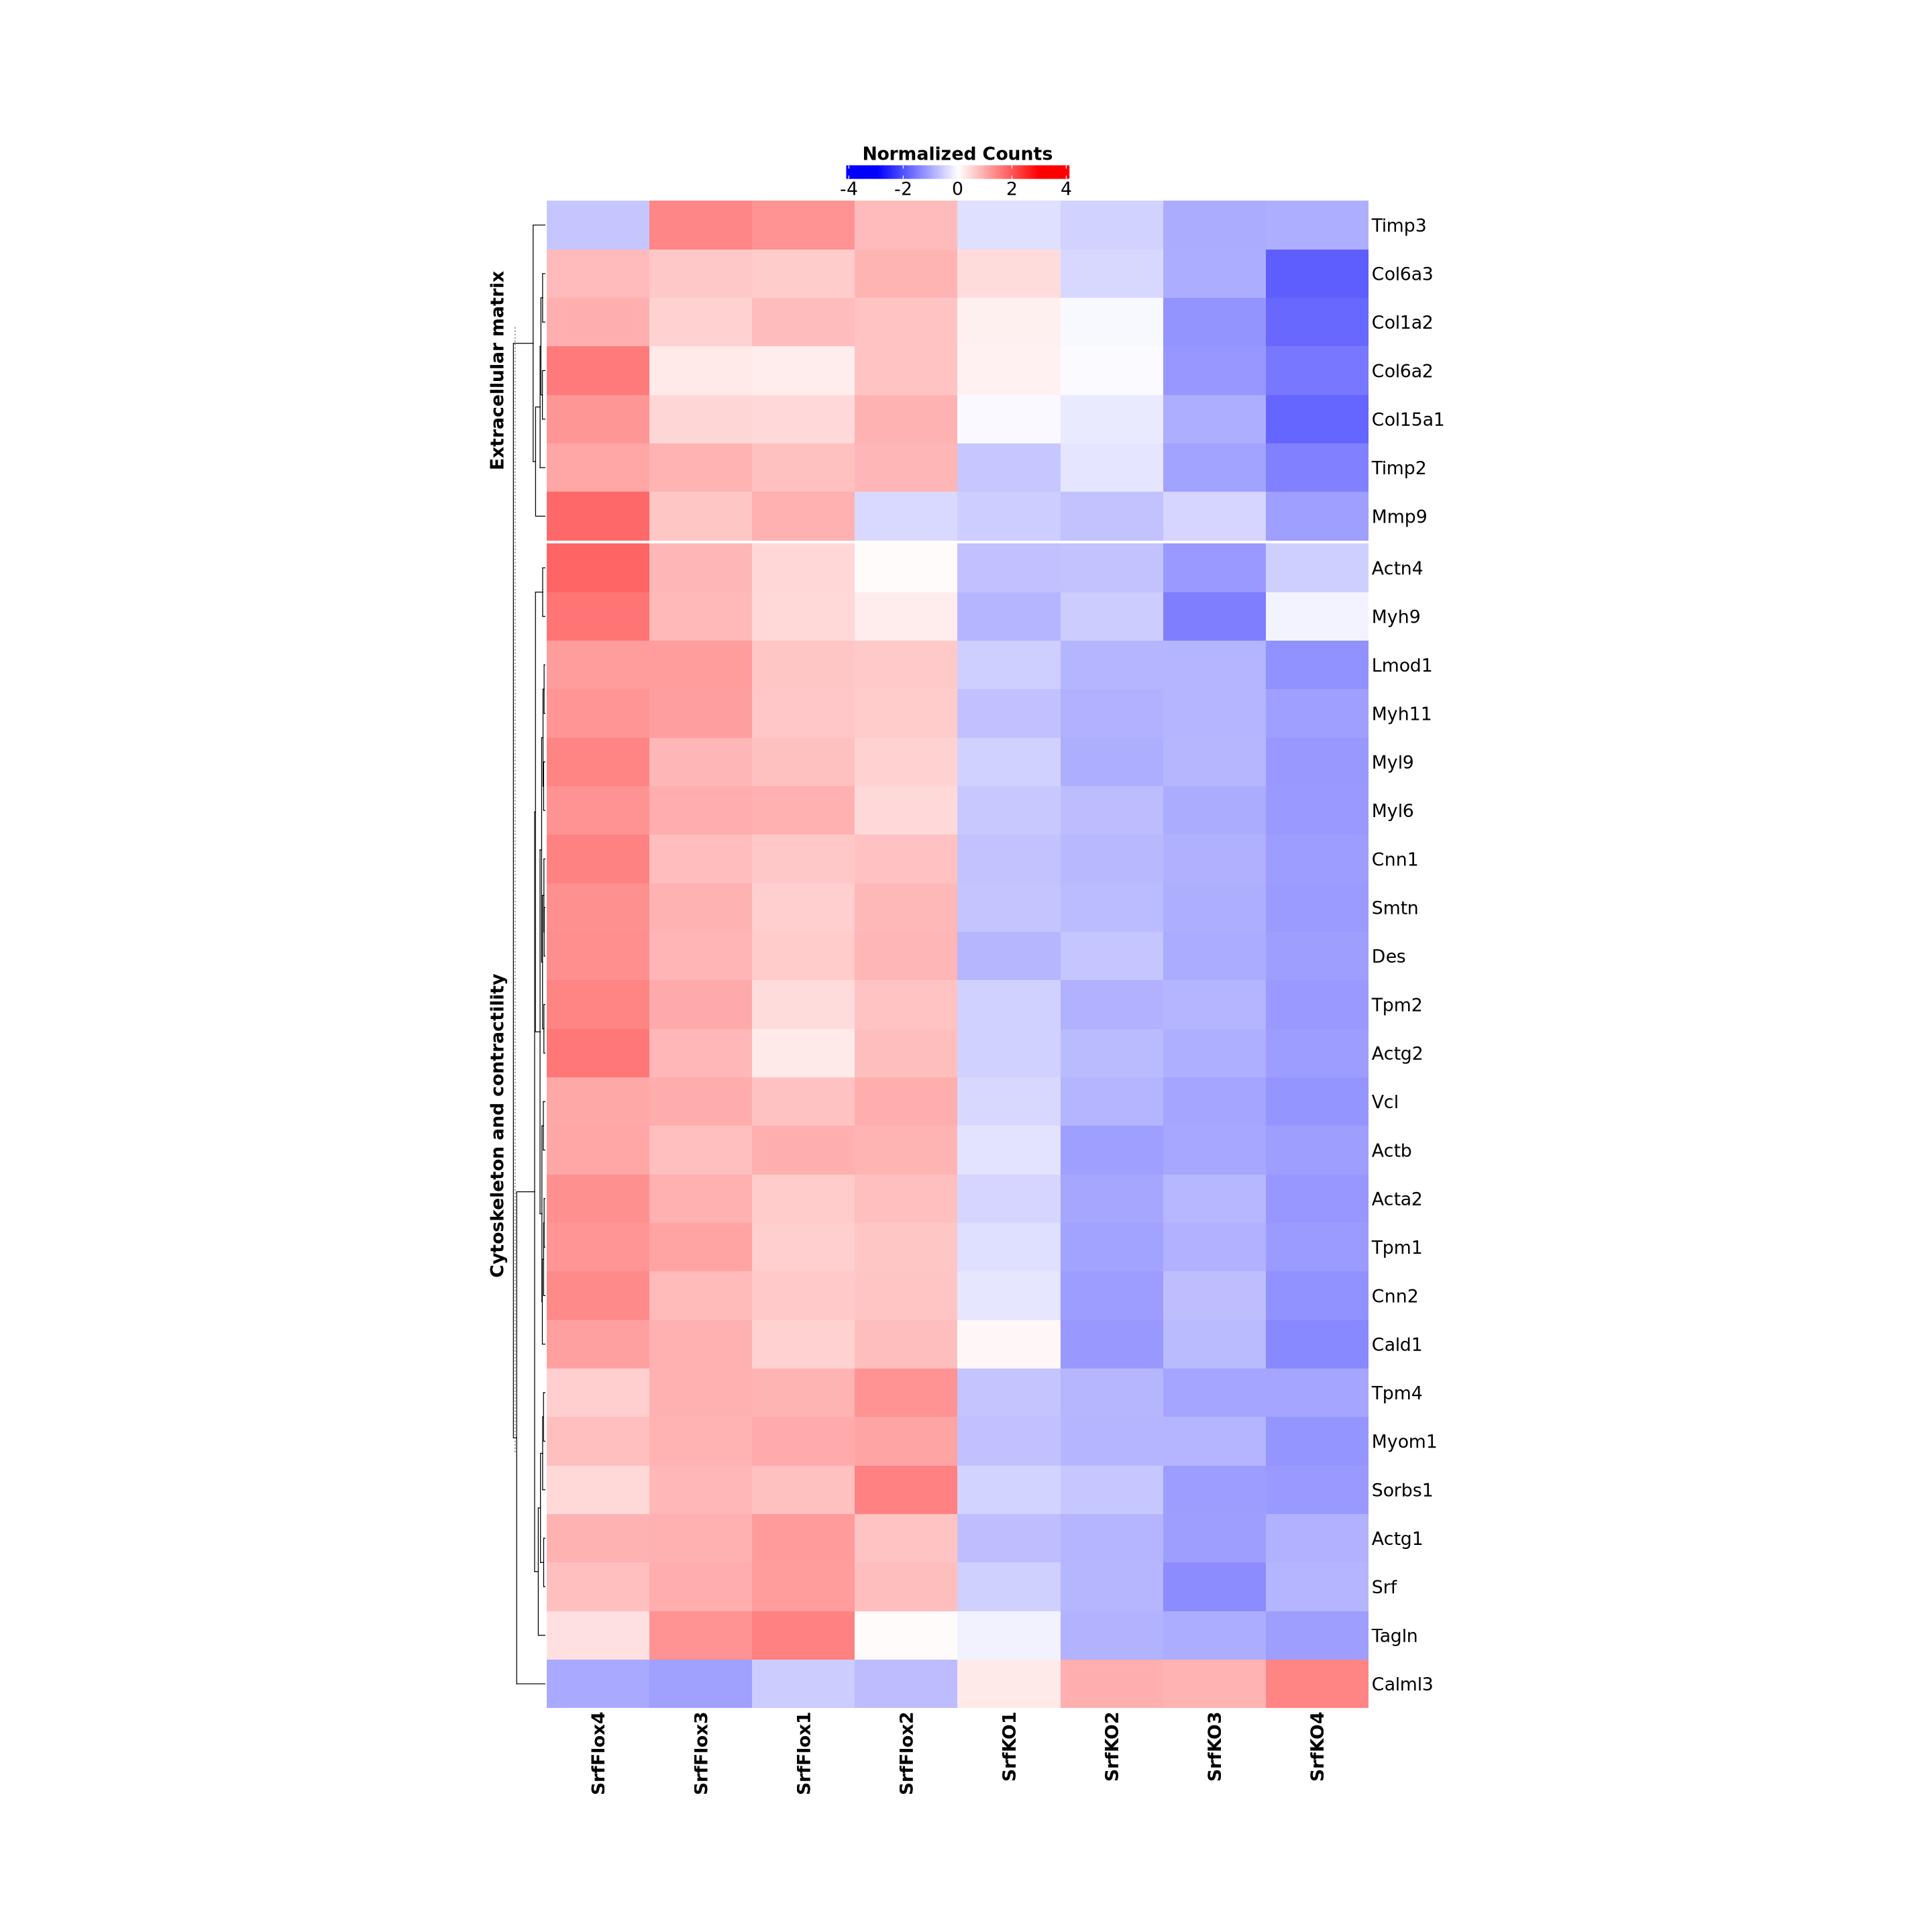

In [67]:
# draw again without right side annotation, adding row titles
# rotate labels

saved <- options(repr.plot.width = 24, repr.plot.height = 24) # Make the plots bigger from here on out, save old options

set.seed(123)
#Set annotation parameters

RowAnn <- data.frame(df$Annotation)
  colnames(RowAnn) <- c("Annotation")
  colours <- list("Annotation"=c("Cytoskeleton and contractility"="coral", "Extracellular matrix"="darkcyan"))
  RowAnn <- HeatmapAnnotation(df=RowAnn, 
                              col=colours,
                              annotation_name_gp = gpar(fontsize = 16, fontface = "bold"),
                              which="row",
                              annotation_legend_param = list(
                                                title_gp = gpar(fontsize = 16, fontface = "bold"), 
                                                labels_gp = gpar(fontsize = 16)))

myBreaks <- seq(-3, 3, length.out=100)
myCol <- colorRampPalette(c("blue", "white", "red"))(100)

#Set heatmap parameters
hmap <- Heatmap(heat,
        name="Normalized Counts",
        col=colorRamp2(myBreaks, myCol),
        heatmap_width = unit(30,"cm"),
        heatmap_height = unit(50,"cm"),
        column_names_gp = gpar(fontsize = 16, fontface="bold"),
        heatmap_legend_param=list(color_bar="continuous", 
            legend_direction="horizontal", 
            legend_width=unit(7,"cm"), 
            title_position="topcenter", 
            title_gp=gpar(fontsize=16, fontface="bold"),
            labels_gp=gpar(fontsize=16)),

        #Keep column order instead of clustering
        column_order = order(as.numeric(gsub("column", "", colnames(heat)))),
                
        #Split heatmap rows by annotation
        split=df$Annotation,

        #Row annotation configurations
        cluster_rows=TRUE,
        show_row_dend=TRUE,
        row_title_side="left",
        row_title_gp=gpar(fontsize=16, fontface="bold"),
        show_row_names=TRUE,
        row_names_side="right",
        row_names_gp=gpar(fontsize=16),
        row_names_rot=0,
        row_title_rot=90,

        #Column annotation configuratiions
        cluster_columns=FALSE,
        show_column_dend=FALSE,
        column_title="",
        column_title_side="top",
        column_title_gp=gpar(fontsize=15, fontface="bold"),
        column_title_rot=0,
        show_column_names=TRUE,

        
                
        #Dendrogram configurations: rows
        clustering_distance_rows="euclidean",
        clustering_method_rows="ward.D2",
        row_dend_width=unit(10,"mm"))

        #Annotations (row annotation must be added with 'draw' function, below)
        


draw(hmap, heatmap_legend_side="top")

options(saved) # restore old settings

# Annotate selected genes instead of color-coding annotation groups

Warning message in order(as.numeric(gsub("column", "", colnames(heat)))):
“NAs introduced by coercion”


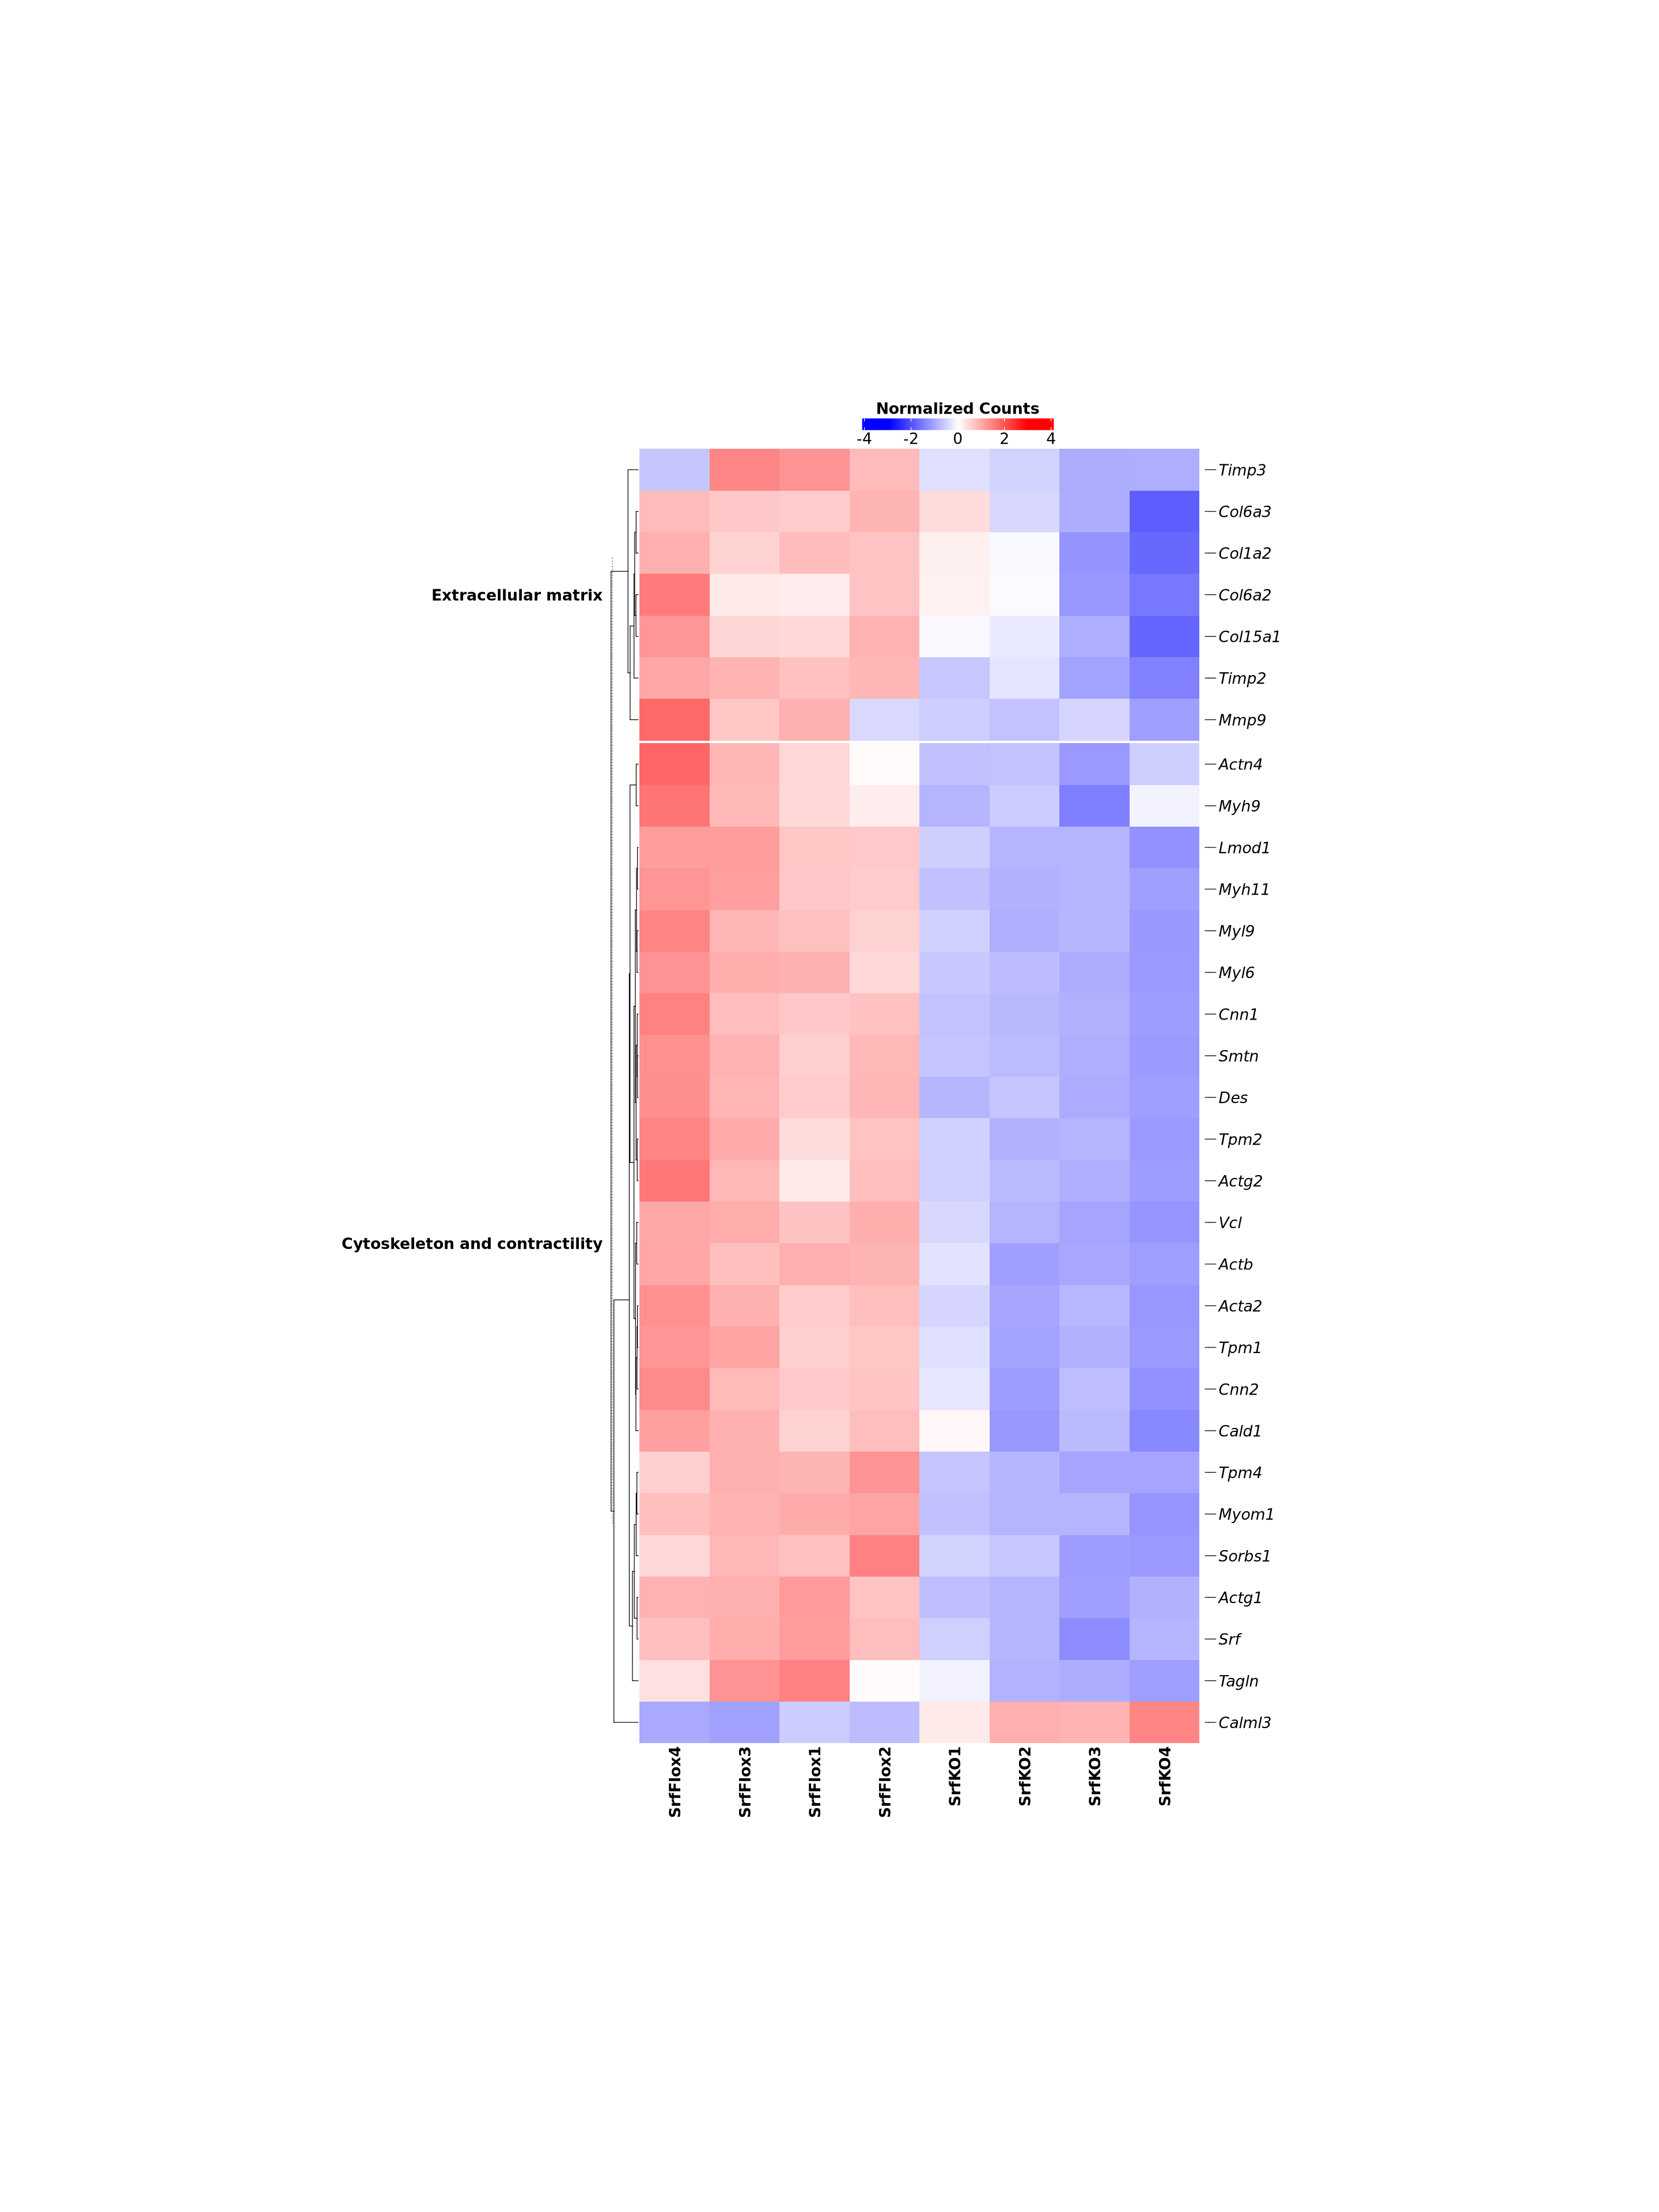

In [37]:
# draw again, now with right side annotation of specific genes
# See https://jokergoo.github.io/ComplexHeatmap-reference/book/heatmap-annotations.html#mark-annotation
# Also got some help from chatGPT to modify the code

saved <- options(repr.plot.width = 24, repr.plot.height = 32) # Make the plots bigger from here on out, save old options

set.seed(123)

# Generate heatmap colors
myBreaks <- seq(-3, 3, length.out = 100)
myCol <- colorRampPalette(c("blue", "white", "red"))(100)

# Define rows to mark
rows_to_mark <- c("Myh11", "Cnn1", "Actg2", "Des", "Tpm2", "Acta2", "Myl9", "Smtn", 
                  "Tagln", "Lmod1", "Myom1", "Cnn2", "Mmp9", "Srf", "Tpm1", "Actg1", "Timp3", 
                  "Sorbs1", "Cald1", "Myl6", "Col1a2", "Actb", "Tpm4", "Col6a2", "Timp2", 
                  "Col6a3", "Col15a1", "Vcl", "Myh9", "Actn4", "Calml3"
                  )       
mark_indices <- match(rows_to_mark, rownames(heat))  # Get row indices

# Add row annotations using anno_mark
RowAnn <- rowAnnotation(
  mark = anno_mark(
    at = mark_indices,                 # Row indices to mark
    labels = rows_to_mark,             # Labels for the marked rows
    labels_gp = gpar(fontsize = 16, fontface = "italic"),   # Font size for labels
    link_gp = gpar(lwd = 1, col = "black") # Line properties
  )
)

# Set heatmap parameters
hmap <- Heatmap(
  heat,
  name = "Normalized Counts",
  col = colorRamp2(myBreaks, myCol),
  heatmap_width = unit(30, "cm"),
  heatmap_height = unit(50, "cm"),
  column_names_gp = gpar(fontsize = 16, fontface = "bold"),
  heatmap_legend_param = list(
    color_bar = "continuous",
    legend_direction = "horizontal",
    legend_width = unit(7, "cm"),
    title_position = "topcenter",
    title_gp = gpar(fontsize = 16, fontface = "bold"),
    labels_gp = gpar(fontsize = 16)
  ),
  
    # Keep column order instead of clustering
  column_order = order(as.numeric(gsub("column", "", colnames(heat)))),
  
    # Split heatmap rows by annotation
  split = df$Annotation,
  
    # Row annotation configurations
  cluster_rows = TRUE,
  show_row_dend = TRUE,
  row_title_side = "left",
  row_title_gp = gpar(fontsize = 16, fontface = "bold"),
  show_row_names = TRUE,
  row_names_side = "right",
  row_names_gp = gpar(fontsize = 5.5),
  row_names_rot = 0,
  row_title_rot = 0,
  # Column annotation configurations
  cluster_columns = FALSE,
  show_column_dend = FALSE,
  column_title = "",
  column_title_side = "top",
  column_title_gp = gpar(fontsize = 15, fontface = "bold"),
  column_title_rot = 0,
  show_column_names = TRUE,
  # Dendrogram configurations: rows
  clustering_distance_rows = "euclidean",
  clustering_method_rows = "ward.D2",
  row_dend_width = unit(10, "mm")
)

# Draw heatmap with row annotations
draw(hmap + RowAnn, heatmap_legend_side = "top")

options(saved) # restore old settings


Warning message in order(as.numeric(gsub("column", "", colnames(heat)))):
“NAs introduced by coercion”


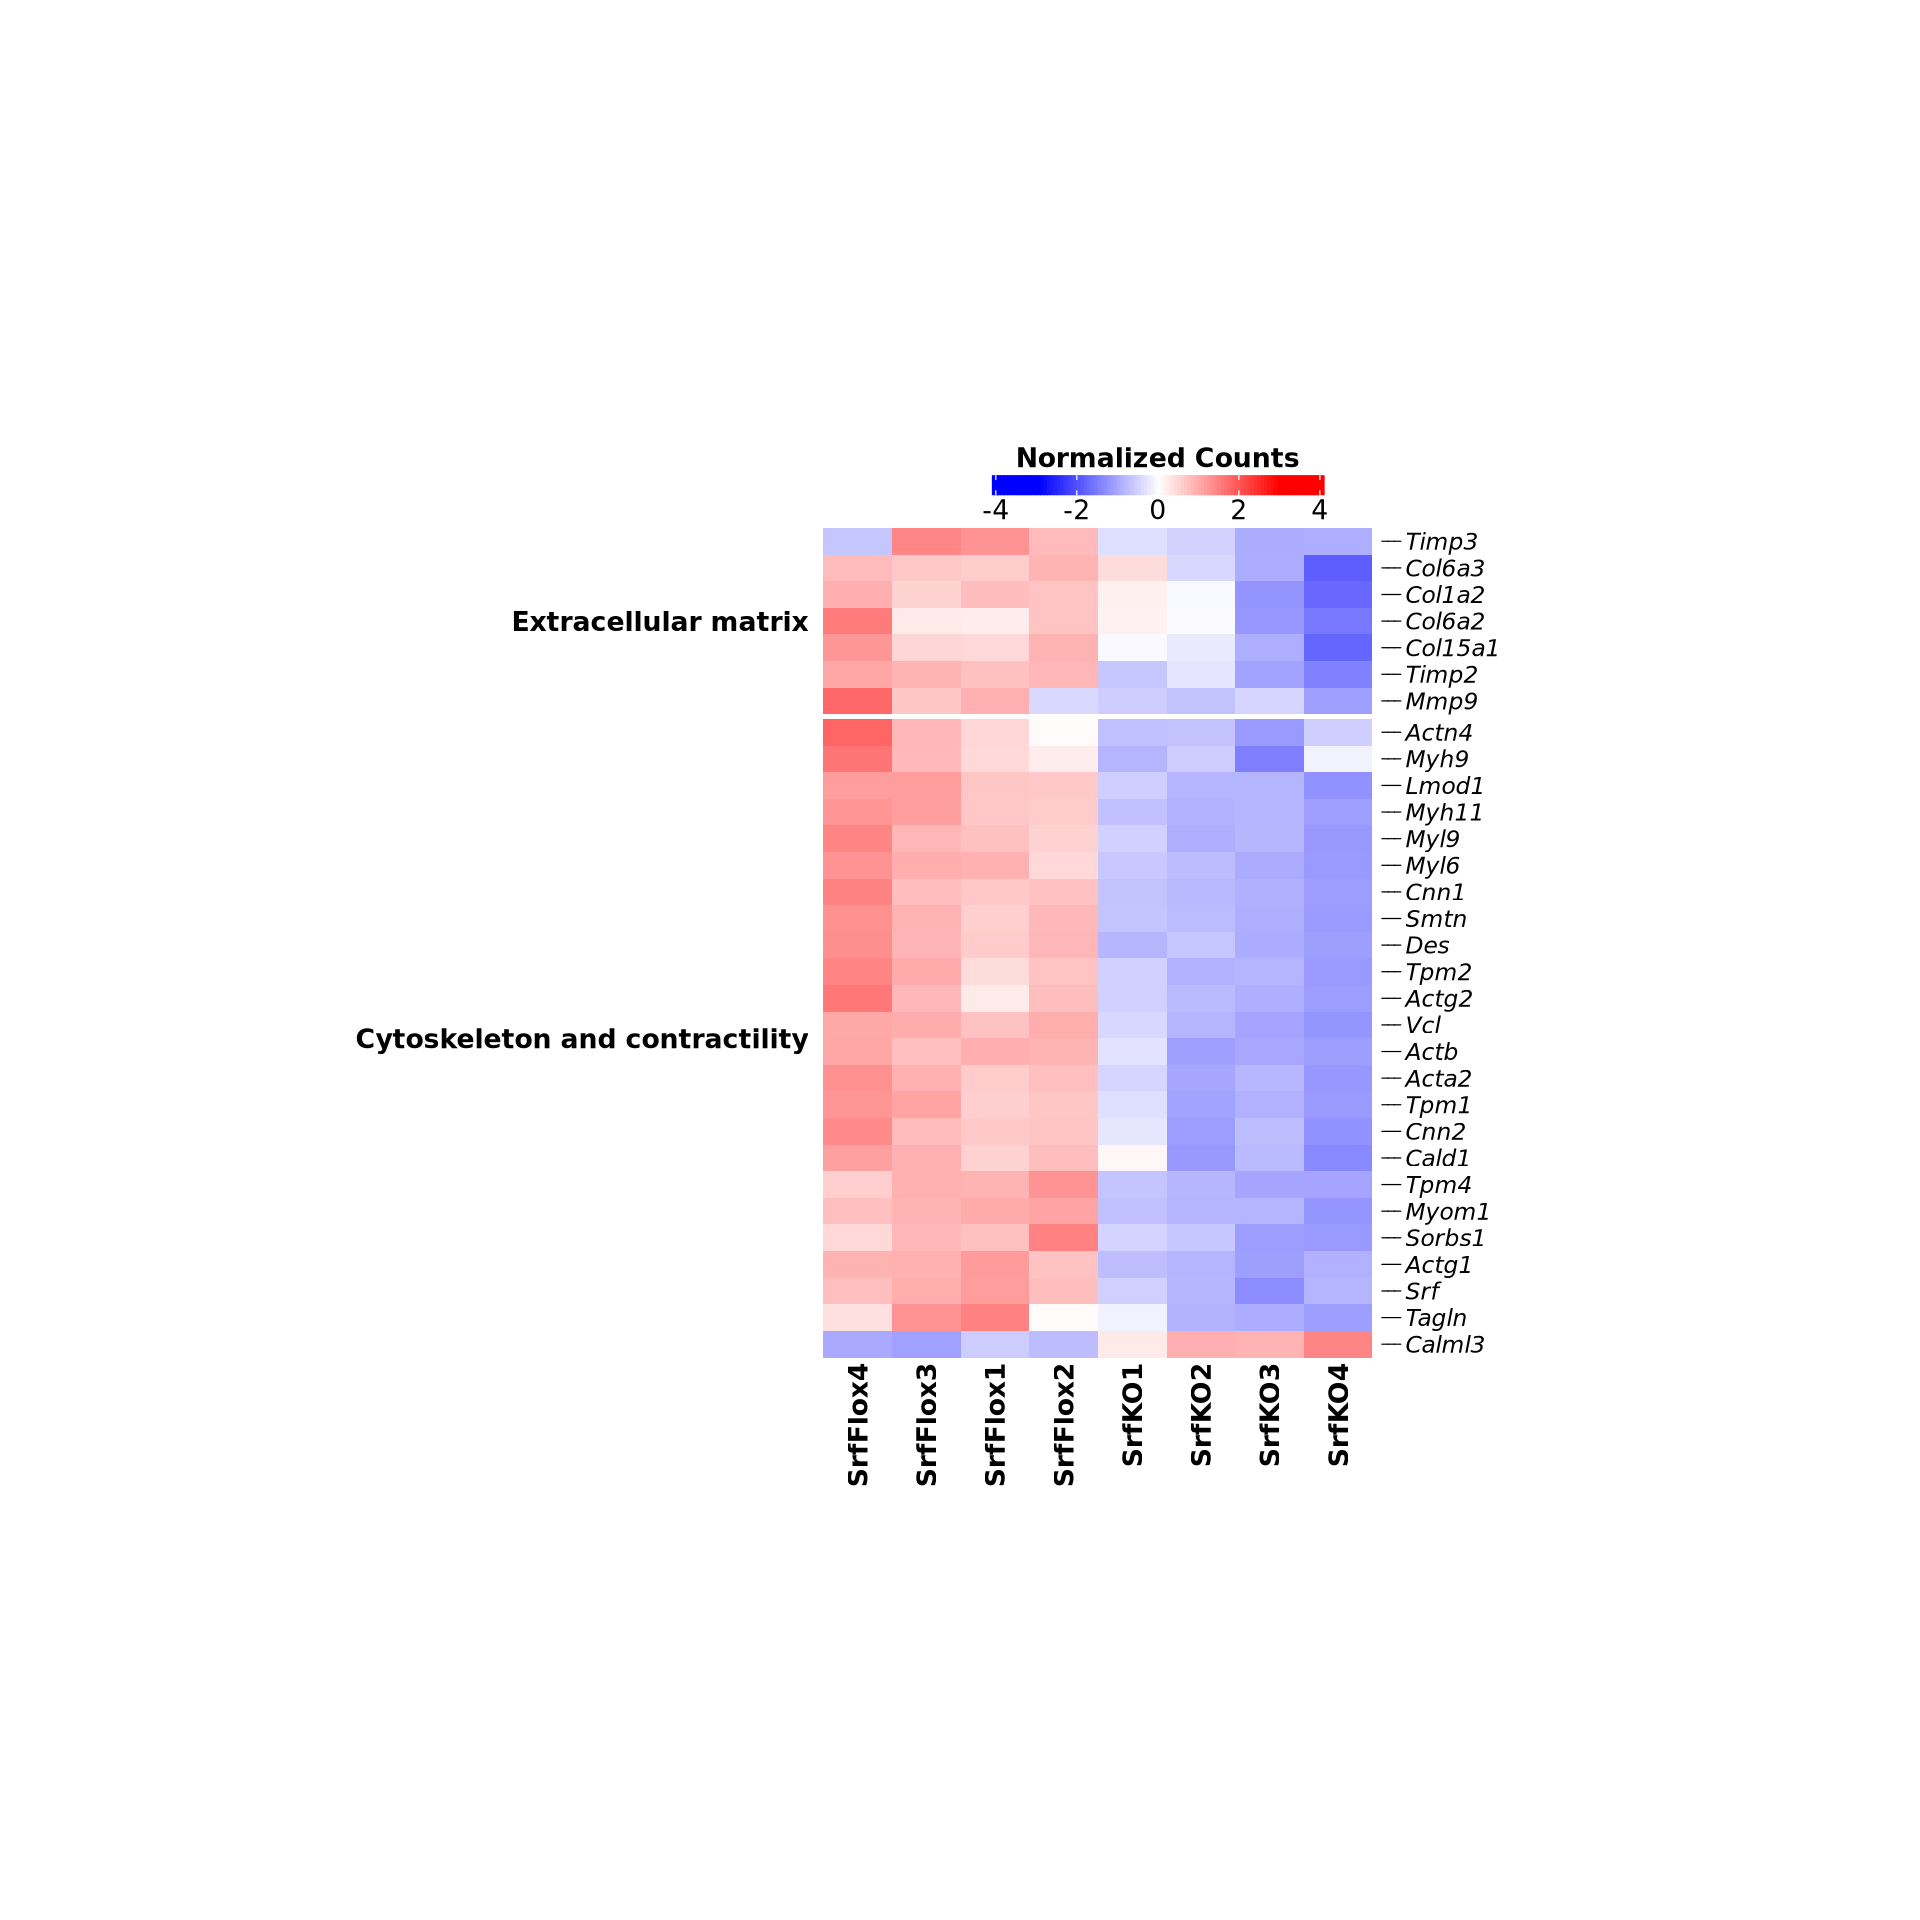

In [41]:
# Mark all genes, remove dendrogram

# draw again, now with right side annotation of specific genes
# See https://jokergoo.github.io/ComplexHeatmap-reference/book/heatmap-annotations.html#mark-annotation
# Also got some help from chatGPT to modify the code

saved <- options(repr.plot.width = 16, repr.plot.height = 16) # Make the plots bigger from here on out, save old options

set.seed(123)

# Generate heatmap colors
myBreaks <- seq(-3, 3, length.out = 100)
myCol <- colorRampPalette(c("blue", "white", "red"))(100)

# Define rows to mark
rows_to_mark <- c("Myh11", "Cnn1", "Actg2", "Des", "Tpm2", "Acta2", "Myl9", "Smtn", 
                  "Tagln", "Lmod1", "Myom1", "Cnn2", "Mmp9", "Srf", "Tpm1", "Actg1", "Timp3", 
                  "Sorbs1", "Cald1", "Myl6", "Col1a2", "Actb", "Tpm4", "Col6a2", "Timp2", 
                  "Col6a3", "Col15a1", "Vcl", "Myh9", "Actn4", "Calml3"
                  )       
mark_indices <- match(rows_to_mark, rownames(heat))  # Get row indices

# Add row annotations using anno_mark
RowAnn <- rowAnnotation(
  mark = anno_mark(
    at = mark_indices,                 # Row indices to mark
    labels = rows_to_mark,             # Labels for the marked rows
    labels_gp = gpar(fontsize = 14, fontface = "italic"),   # Font size for labels
    link_gp = gpar(lwd = 1, col = "black") # Line properties
  )
)

# Set heatmap parameters
hmap <- Heatmap(
  heat,
  name = "Normalized Counts",
  col = colorRamp2(myBreaks, myCol),
  heatmap_width = unit(20, "cm"),
  heatmap_height = unit(20, "cm"),
  column_names_gp = gpar(fontsize = 16, fontface = "bold"),
  heatmap_legend_param = list(
    color_bar = "continuous",
    legend_direction = "horizontal",
    legend_width = unit(7, "cm"),
    title_position = "topcenter",
    title_gp = gpar(fontsize = 16, fontface = "bold"),
    labels_gp = gpar(fontsize = 16)
  ),
  
    # Keep column order instead of clustering
  column_order = order(as.numeric(gsub("column", "", colnames(heat)))),
  
    # Split heatmap rows by annotation
  split = df$Annotation,
  
    # Row annotation configurations
  cluster_rows = TRUE,
  show_row_dend = FALSE,
  row_title_side = "left",
  row_title_gp = gpar(fontsize = 16, fontface = "bold"),
  show_row_names = TRUE,
  row_names_side = "right",
  row_names_gp = gpar(fontsize = 5.5),
  row_names_rot = 0,
  row_title_rot = 0,
  # Column annotation configurations
  cluster_columns = FALSE,
  show_column_dend = FALSE,
  column_title = "",
  column_title_side = "top",
  column_title_gp = gpar(fontsize = 15, fontface = "bold"),
  column_title_rot = 0,
  show_column_names = TRUE,
  # Dendrogram configurations: rows
  clustering_distance_rows = "euclidean",
  clustering_method_rows = "ward.D2",
  row_dend_width = unit(10, "mm")
)

# Draw heatmap with row annotations
draw(hmap + RowAnn, heatmap_legend_side = "top")

options(saved) # restore old settings


Warning message in order(as.numeric(gsub("column", "", colnames(heat)))):
“NAs introduced by coercion”


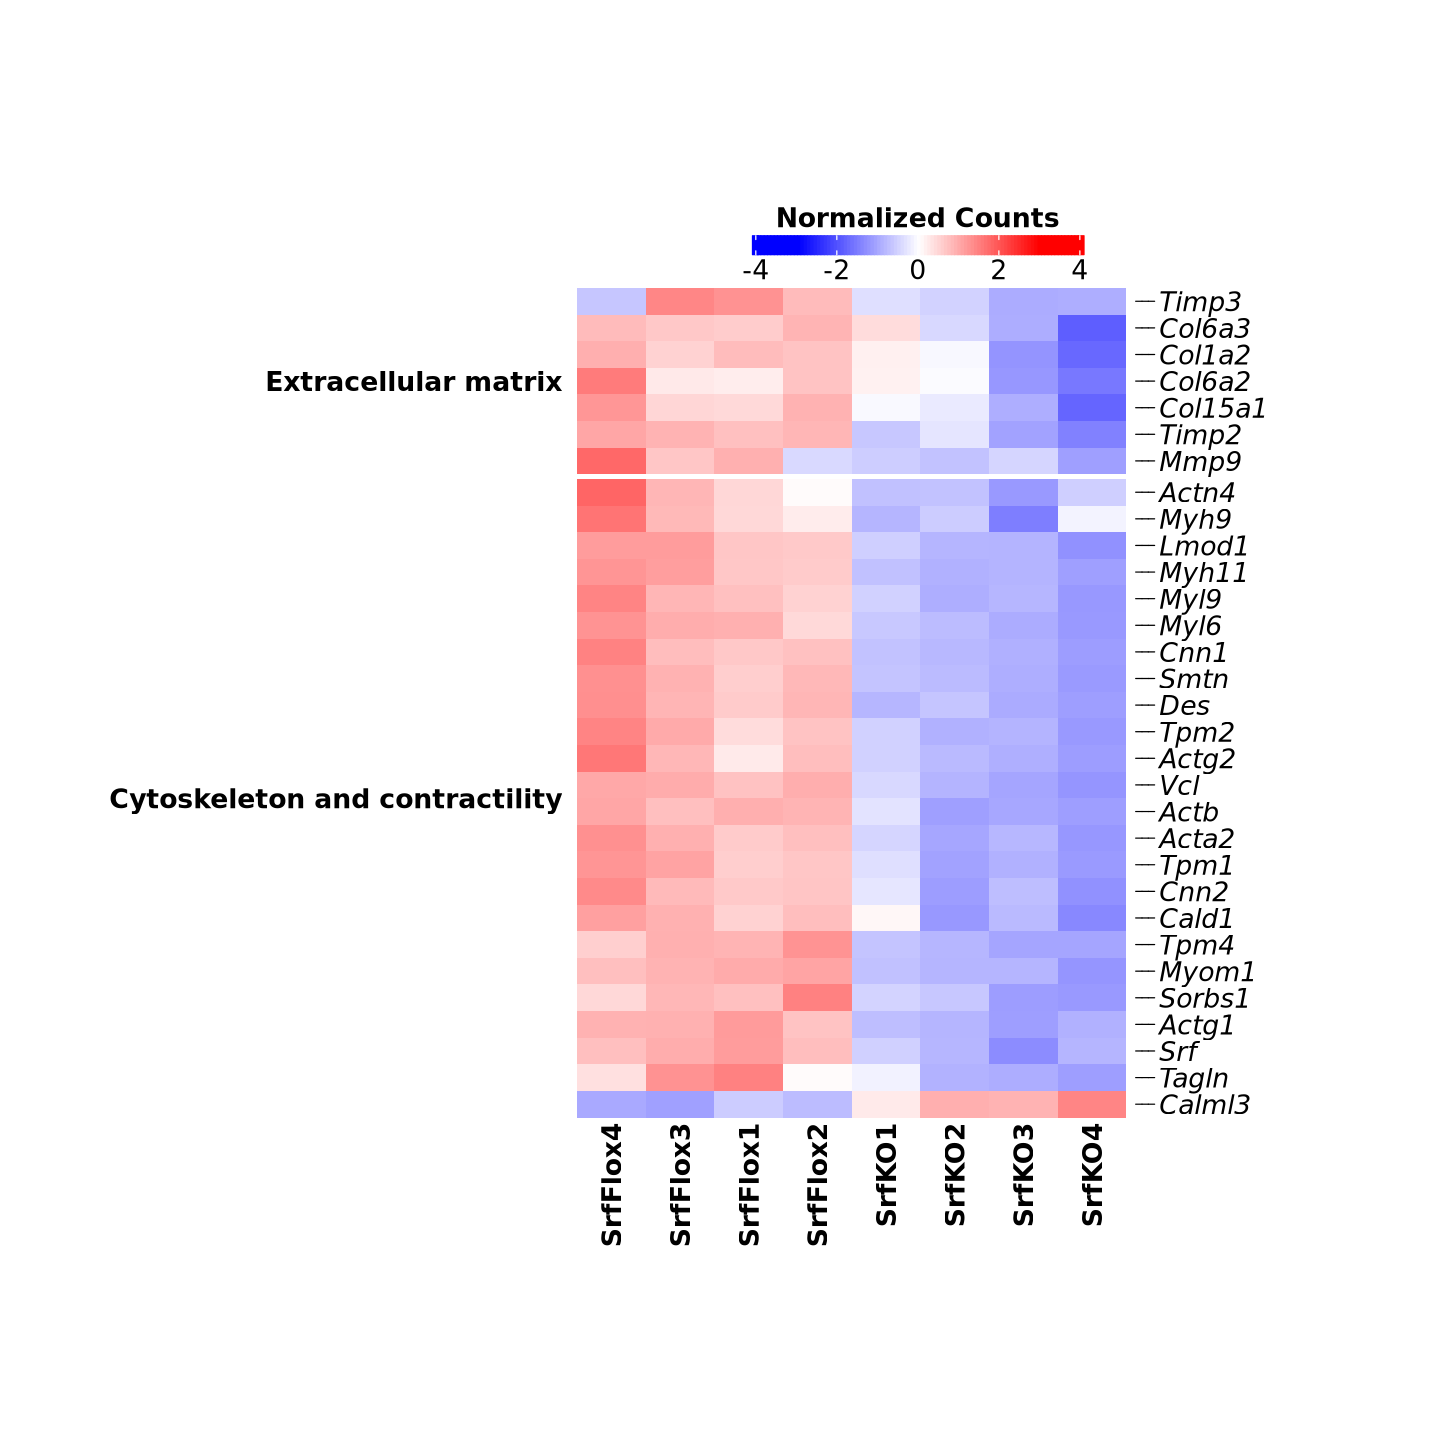

In [44]:
# draw again, now with right side annotation of specific genes
# See https://jokergoo.github.io/ComplexHeatmap-reference/book/heatmap-annotations.html#mark-annotation
# Also got some help from chatGPT to modify the code

saved <- options(repr.plot.width = 12, repr.plot.height = 12) # Make the plots bigger from here on out, save old options

set.seed(123)

# Generate heatmap colors
myBreaks <- seq(-3, 3, length.out = 100)
myCol <- colorRampPalette(c("blue", "white", "red"))(100)

# Define rows to mark
rows_to_mark <- c("Myh11", "Cnn1", "Actg2", "Des", "Tpm2", "Acta2", "Myl9", "Smtn", 
                  "Tagln", "Lmod1", "Myom1", "Cnn2", "Mmp9", "Srf", "Tpm1", "Actg1", "Timp3", 
                  "Sorbs1", "Cald1", "Myl6", "Col1a2", "Actb", "Tpm4", "Col6a2", "Timp2", 
                  "Col6a3", "Col15a1", "Vcl", "Myh9", "Actn4", "Calml3"
                  )        
mark_indices <- match(rows_to_mark, rownames(heat))  # Get row indices

# Add row annotations using anno_mark
RowAnn <- rowAnnotation(
  mark = anno_mark(
    at = mark_indices,                 # Row indices to mark
    labels = rows_to_mark,             # Labels for the marked rows
    labels_gp = gpar(fontsize = 16, fontface = "italic"),   # Font size for labels
    link_gp = gpar(lwd = 1, col = "black") # Line properties
  )
)

# Set heatmap parameters
hmap <- Heatmap(
  heat,
  name = "Normalized Counts",
  col = colorRamp2(myBreaks, myCol),
  heatmap_width = unit(20, "cm"),
  heatmap_height = unit(20, "cm"),
  column_names_gp = gpar(fontsize = 16, fontface = "bold"),
  heatmap_legend_param = list(
    color_bar = "continuous",
    legend_direction = "horizontal",
    legend_width = unit(7, "cm"),
    title_position = "topcenter",
    title_gp = gpar(fontsize = 16, fontface = "bold"),
    labels_gp = gpar(fontsize = 16)
  ),
  
    # Keep column order instead of clustering
  column_order = order(as.numeric(gsub("column", "", colnames(heat)))),
  
    # Split heatmap rows by annotation
  split = df$Annotation,
  
    # Row annotation configurations
  cluster_rows = TRUE,
  show_row_dend = FALSE,
  row_title_side = "left",
  row_title_gp = gpar(fontsize = 16, fontface = "bold"),
  show_row_names = TRUE,
  row_names_side = "right",
  row_names_gp = gpar(fontsize = 5.5),
  row_names_rot = 0,
  row_title_rot = 0,
  # Column annotation configurations
  cluster_columns = FALSE,
  show_column_dend = FALSE,
  column_title = "",
  column_title_side = "top",
  column_title_gp = gpar(fontsize = 15, fontface = "bold"),
  column_title_rot = 0,
  show_column_names = TRUE,
  # Dendrogram configurations: rows
  clustering_distance_rows = "euclidean",
  clustering_method_rows = "ward.D2",
  row_dend_width = unit(10, "mm")
)

# Draw heatmap with row annotations
draw(hmap + RowAnn, heatmap_legend_side = "top")

options(saved) # restore old settings


Warning message in order(as.numeric(gsub("column", "", colnames(heat)))):
“NAs introduced by coercion”


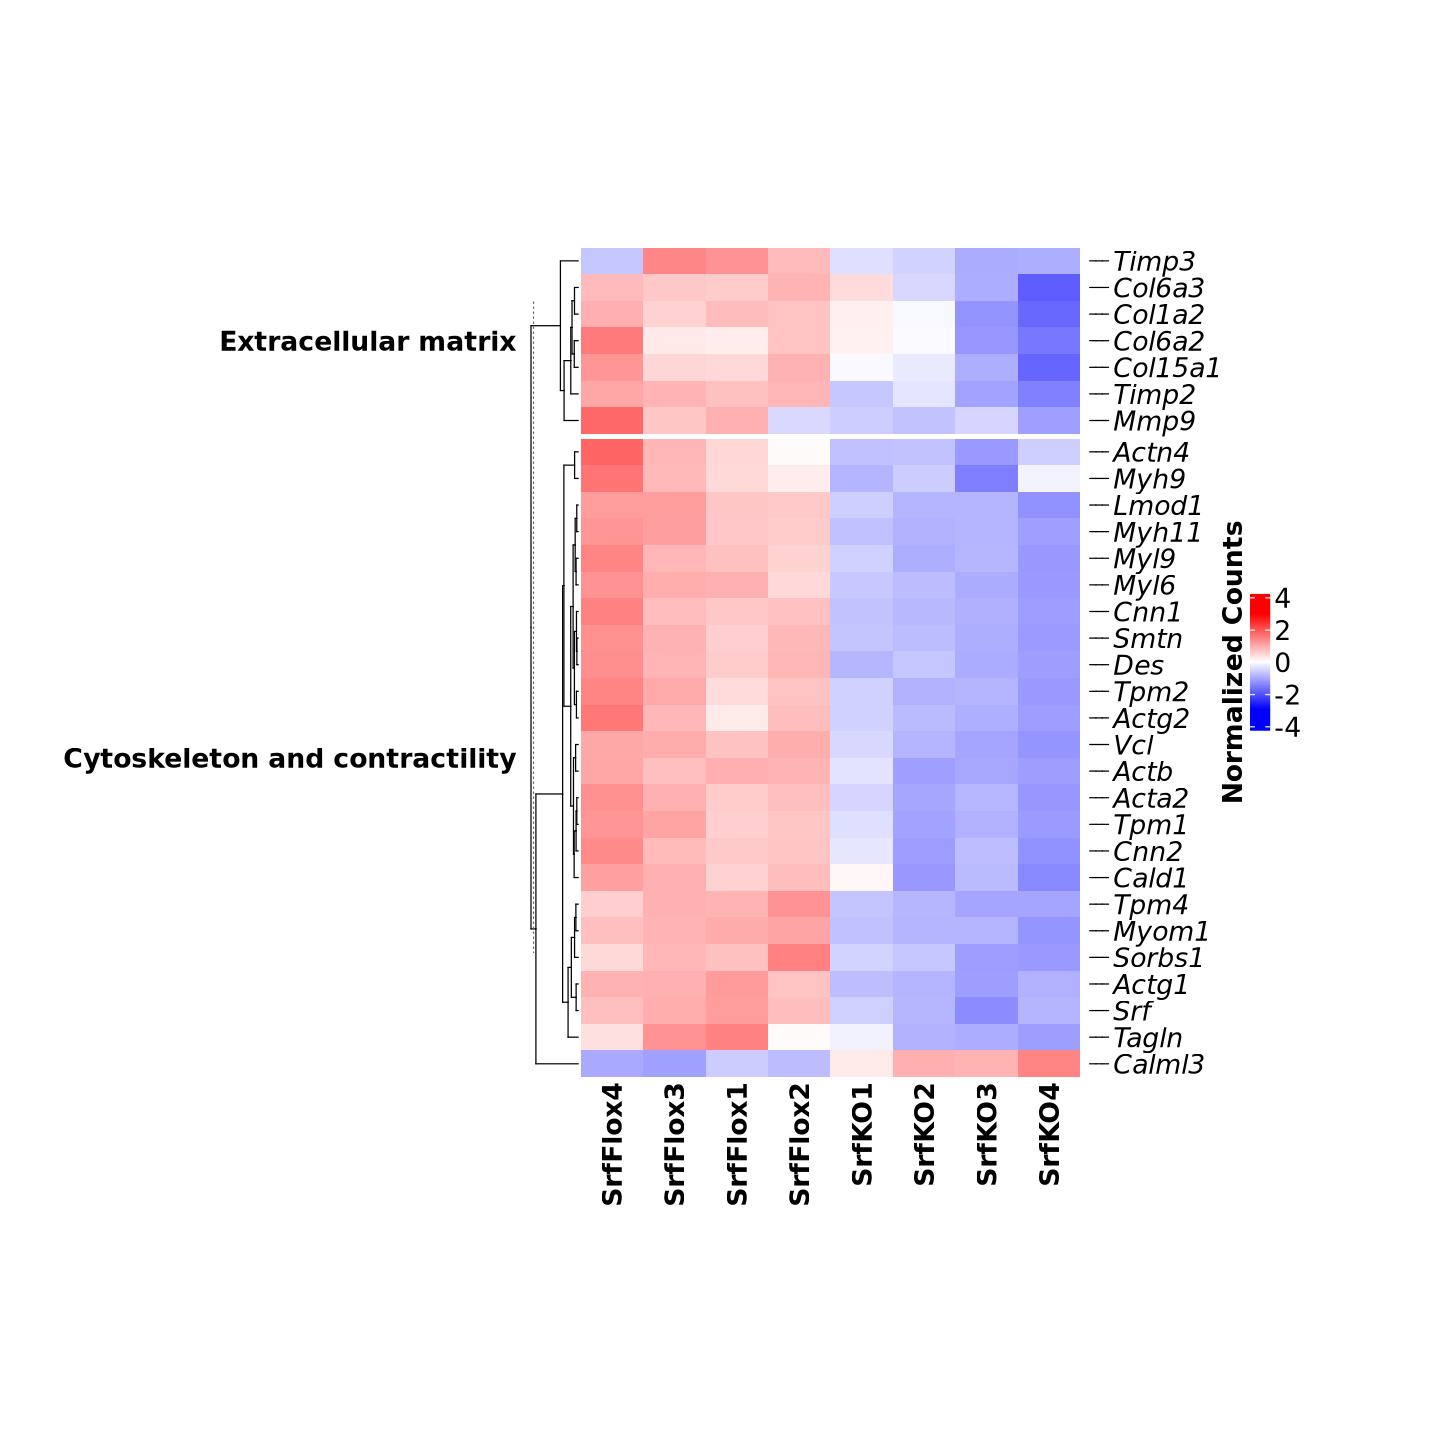

In [72]:
# draw again, now with right side annotation of specific genes, move legend, modify gene selections
# See https://jokergoo.github.io/ComplexHeatmap-reference/book/heatmap-annotations.html#mark-annotation
# Also got some help from chatGPT to modify the code

saved <- options(repr.plot.width = 12, repr.plot.height = 12) # Make the plots bigger from here on out, save old options

set.seed(123)

# Generate heatmap colors
myBreaks <- seq(-3, 3, length.out = 100)
myCol <- colorRampPalette(c("blue", "white", "red"))(100)

# Define rows to mark
rows_to_mark <- c("Myh11", "Cnn1", "Actg2", "Des", "Tpm2", "Acta2", "Myl9", "Smtn", 
                  "Tagln", "Lmod1", "Myom1", "Cnn2", "Mmp9", "Srf", "Tpm1", "Actg1", "Timp3", 
                  "Sorbs1", "Cald1", "Myl6", "Col1a2", "Actb", "Tpm4", "Col6a2", "Timp2", 
                  "Col6a3", "Col15a1", "Vcl", "Myh9", "Actn4", "Calml3"
                  )    
mark_indices <- match(rows_to_mark, rownames(heat))  # Get row indices

# Add row annotations using anno_mark
RowAnn <- rowAnnotation(
  mark = anno_mark(
    at = mark_indices,                 # Row indices to mark
    labels = rows_to_mark,             # Labels for the marked rows
    labels_gp = gpar(fontsize = 16, fontface = "italic"),   # Font size for labels
    link_gp = gpar(lwd = 1, col = "black") # Line properties
  )
)

# Set heatmap parameters
hmap <- Heatmap(
  heat,
  name = "Normalized Counts",
  col = colorRamp2(myBreaks, myCol),
  heatmap_width = unit(20, "cm"),
  heatmap_height = unit(20, "cm"),
  column_names_gp = gpar(fontsize = 16, fontface = "bold"),
  heatmap_legend_param = list(
    color_bar = "continuous",
    legend_direction = "vertical",
    legend_width = unit(7, "cm"),
    title_position = "leftcenter-rot",
    title_gp = gpar(fontsize = 16, fontface = "bold"),
    labels_gp = gpar(fontsize = 16)
  ),
  
    # Keep column order instead of clustering
  column_order = order(as.numeric(gsub("column", "", colnames(heat)))),
  
    # Split heatmap rows by annotation
  split = df$Annotation,
  
    # Row annotation configurations
  cluster_rows = TRUE,
  show_row_dend = TRUE,
  row_title_side = "left",
  row_title_gp = gpar(fontsize = 16, fontface = "bold"),
  show_row_names = TRUE,
  row_names_side = "right",
  row_names_gp = gpar(fontsize = 5.5),
  row_names_rot = 0,
  row_title_rot = 0,
  # Column annotation configurations
  cluster_columns = FALSE,
  show_column_dend = FALSE,
  column_title = "",
  column_title_side = "top",
  column_title_gp = gpar(fontsize = 15, fontface = "bold"),
  column_title_rot = 0,
  show_column_names = TRUE,
  # Dendrogram configurations: rows
  clustering_distance_rows = "euclidean",
  clustering_method_rows = "ward.D2",
  row_dend_width = unit(10, "mm")
)

# Draw heatmap with row annotations
draw(hmap + RowAnn, heatmap_legend_side = "right")

options(saved) # restore old settings


In [ ]:
# Save plots in image files.
# Do ?png, ?jpeg, ?gif, ?tiff, ?pdf, ?svg for more help.
# Single-cell PDF plots typically take up a lot of space for all the dots you're making.
# File will be saved to the same directory the notebook is in.

# This is setup for later.
plt <- FeaturePlot(SrfFlox_SrfKO,
                   features = c('Rgs5', 'Tagln', 'Cd74'),
                   label = TRUE)

# Open a new PDF file to save figures in.
pdf(file = "test_plots.pdf",
    width = 16,
    height = 16)

# Anything plotted here will become a PDF page...
FeaturePlot(SrfFlox_SrfKO,
            features = c('Acta2', 'Pcp4', 'S100g'),
            label = TRUE)

# even if it's been saved before.
plt

# Note all plots will have the same page size, though. Make new files if you want different sized plots.
FeaturePlot(SrfFlox_SrfKO,
            features = c('Apoe', 'Myh11'),
            label = TRUE)

# Stop plotting to file.
dev.off()

In [79]:
# Save plot as PDF

pdf(file = "251125_Heatmap.pdf",
    width = 12,
    height = 12)

# Generate heatmap colors
myBreaks <- seq(-3, 3, length.out = 100)
myCol <- colorRampPalette(c("blue", "white", "red"))(100)

# Define rows to mark
rows_to_mark <- c("Myh11", "Cnn1", "Actg2", "Des", "Tpm2", "Acta2", "Myl9", "Smtn", 
                  "Tagln", "Lmod1", "Myom1", "Cnn2", "Mmp9", "Srf", "Tpm1", "Actg1", "Timp3", 
                  "Sorbs1", "Cald1", "Myl6", "Col1a2", "Actb", "Tpm4", "Col6a2", "Timp2", 
                  "Col6a3", "Col15a1", "Vcl", "Myh9", "Actn4", "Calml3"
                  )    
mark_indices <- match(rows_to_mark, rownames(heat))  # Get row indices

# Add row annotations using anno_mark
RowAnn <- rowAnnotation(
  mark = anno_mark(
    at = mark_indices,                 # Row indices to mark
    labels = rows_to_mark,             # Labels for the marked rows
    labels_gp = gpar(fontsize = 16, fontface = "italic"),   # Font size for labels
    link_gp = gpar(lwd = 1, col = "black") # Line properties
  )
)

# Set heatmap parameters
hmap <- Heatmap(
  heat,
  name = "Normalized Counts",
  col = colorRamp2(myBreaks, myCol),
  heatmap_width = unit(20, "cm"),
  heatmap_height = unit(20, "cm"),
  column_names_gp = gpar(fontsize = 16, fontface = "bold"),
  heatmap_legend_param = list(
    color_bar = "continuous",
    legend_direction = "vertical",
    legend_width = unit(7, "cm"),
    title_position = "leftcenter-rot",
    title_gp = gpar(fontsize = 16, fontface = "bold"),
    labels_gp = gpar(fontsize = 16)
  ),
  
    # Keep column order instead of clustering
  column_order = order(as.numeric(gsub("column", "", colnames(heat)))),
  
    # Split heatmap rows by annotation
  split = df$Annotation,
  
    # Row annotation configurations
  cluster_rows = TRUE,
  show_row_dend = TRUE,
  row_title_side = "left",
  row_title_gp = gpar(fontsize = 16, fontface = "bold"),
  show_row_names = TRUE,
  row_names_side = "right",
  row_names_gp = gpar(fontsize = 5.5),
  row_names_rot = 0,
  row_title_rot = 0,
  # Column annotation configurations
  cluster_columns = FALSE,
  show_column_dend = FALSE,
  column_title = "",
  column_title_side = "top",
  column_title_gp = gpar(fontsize = 15, fontface = "bold"),
  column_title_rot = 0,
  show_column_names = TRUE,
  # Dendrogram configurations: rows
  clustering_distance_rows = "euclidean",
  clustering_method_rows = "ward.D2",
  row_dend_width = unit(10, "mm")
)

# Draw heatmap with row annotations
draw(hmap + RowAnn, heatmap_legend_side = "right")

# Stop plotting to file.
dev.off()

Warning message in order(as.numeric(gsub("column", "", colnames(heat)))):
“NAs introduced by coercion”


agg_record_603520649 
                   2

In [80]:
# Save plot as SVG

svg(file = "251125_Heatmap.svg",
    width = 12,
    height = 12)

# Generate heatmap colors
myBreaks <- seq(-3, 3, length.out = 100)
myCol <- colorRampPalette(c("blue", "white", "red"))(100)

# Define rows to mark
rows_to_mark <- c("Myh11", "Cnn1", "Actg2", "Des", "Tpm2", "Acta2", "Myl9", "Smtn", 
                  "Tagln", "Lmod1", "Myom1", "Cnn2", "Mmp9", "Srf", "Tpm1", "Actg1", "Timp3", 
                  "Sorbs1", "Cald1", "Myl6", "Col1a2", "Actb", "Tpm4", "Col6a2", "Timp2", 
                  "Col6a3", "Col15a1", "Vcl", "Myh9", "Actn4", "Calml3"
                  )    
mark_indices <- match(rows_to_mark, rownames(heat))  # Get row indices

# Add row annotations using anno_mark
RowAnn <- rowAnnotation(
  mark = anno_mark(
    at = mark_indices,                 # Row indices to mark
    labels = rows_to_mark,             # Labels for the marked rows
    labels_gp = gpar(fontsize = 16, fontface = "italic"),   # Font size for labels
    link_gp = gpar(lwd = 1, col = "black") # Line properties
  )
)

# Set heatmap parameters
hmap <- Heatmap(
  heat,
  name = "Normalized Counts",
  col = colorRamp2(myBreaks, myCol),
  heatmap_width = unit(20, "cm"),
  heatmap_height = unit(20, "cm"),
  column_names_gp = gpar(fontsize = 16, fontface = "bold"),
  heatmap_legend_param = list(
    color_bar = "continuous",
    legend_direction = "vertical",
    legend_width = unit(7, "cm"),
    title_position = "leftcenter-rot",
    title_gp = gpar(fontsize = 16, fontface = "bold"),
    labels_gp = gpar(fontsize = 16)
  ),
  
    # Keep column order instead of clustering
  column_order = order(as.numeric(gsub("column", "", colnames(heat)))),
  
    # Split heatmap rows by annotation
  split = df$Annotation,
  
    # Row annotation configurations
  cluster_rows = TRUE,
  show_row_dend = TRUE,
  row_title_side = "left",
  row_title_gp = gpar(fontsize = 16, fontface = "bold"),
  show_row_names = TRUE,
  row_names_side = "right",
  row_names_gp = gpar(fontsize = 5.5),
  row_names_rot = 0,
  row_title_rot = 0,
  # Column annotation configurations
  cluster_columns = FALSE,
  show_column_dend = FALSE,
  column_title = "",
  column_title_side = "top",
  column_title_gp = gpar(fontsize = 15, fontface = "bold"),
  column_title_rot = 0,
  show_column_names = TRUE,
  # Dendrogram configurations: rows
  clustering_distance_rows = "euclidean",
  clustering_method_rows = "ward.D2",
  row_dend_width = unit(10, "mm")
)

# Draw heatmap with row annotations
draw(hmap + RowAnn, heatmap_legend_side = "right")

# Stop plotting to file.
dev.off()

Warning message in order(as.numeric(gsub("column", "", colnames(heat)))):
“NAs introduced by coercion”


agg_record_189241370 
                   2

In [1]:
sessionInfo()

R version 4.3.1 (2023-06-16)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: Rocky Linux 8.10 (Green Obsidian)

Matrix products: default
BLAS/LAPACK: /ddn/gs1/home/marquardtrm/miniforge3/envs/r431/lib/libopenblasp-r0.3.30.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: America/New_York
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

loaded via a namespace (and not attached):
 [1] digest_0.6.37     IRdisplay_1.1     base64enc_0.1-3   fastmap_1.2.0    
 [5] glue_1.8.0        htmltools_0.5.8.1 repr_1.1.7        lifecycle_1.0.4  
 [9] cli_3.6.5         